# GTA Housing Market – Regression Analysis

Synthetic Greater Toronto Area listings, **January 2021 – May 2026**, 150,000 rows. Same layout as the cancer-type notebook (imports → EDA → preprocessing → model comparison → tuning → evaluation → explainability), adapted from classification to regression.

**Modelling choices made up front (change them in the config cell if they are not what you want)**

| Topic | Decision | Why |
|---|---|---|
| Target | `sold_price` (the column the schema marks as target). Set `TARGET = "list_price"` to model the listing price instead. | Your message says *listing price*, the schema says *sold_price (target)*. The notebook handles both and drops the matching leakage columns automatically. |
| Leakage | `date_sold`, `days_on_market` are always dropped (only known after the sale). `list_price` is dropped when the target is `sold_price` (it is ~ the target); the sold price is dropped when the target is `list_price`. | Otherwise every model just re-learns the other price. |
| External AVM | Kept as a feature, but its value is blanked when the estimate is dated *after* the event being predicted. | An estimate made after the sale may have seen the sale price. |
| Log regression | Interpreted as **log-linear regression**: `log(price) ~ predictors` (plus a log-log variant). Predictors are the ones you pick from the ANOVA. | Prices are right-skewed, errors are multiplicative. |
| `remarks` | Only `remarks_len` is used (no text features). | As you argued: the text is LLM-written, the *length* tracks how much information the generator was given. The notebook tests that claim instead of assuming it. |
| Validation | 5-fold shuffled CV on all rows; every preprocessing step lives **inside** the CV pipeline (the lesson from the cancer notebook). | No leakage from imputers, scalers or target encoders. |

## Imports

In [1]:
import os, re, warnings, joblib
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from time import time
from joblib import Parallel, delayed
from scipy import stats
from scipy.stats import randint, uniform, loguniform
from scipy.interpolate import make_smoothing_spline

# sklearn: base classes, preprocessing, CV
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, OneHotEncoder, OrdinalEncoder, TargetEncoder,
                                   SplineTransformer, FunctionTransformer)
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import KFold, GridSearchCV, RandomizedSearchCV

# sklearn: models
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV
from sklearn.svm import SVR, LinearSVR
from sklearn.kernel_approximation import Nystroem
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.inspection import permutation_importance

# statistics / additive models / boosting
import patsy
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from pygam import LinearGAM, s, f, te
from xgboost import XGBRegressor

from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 120
print("All imports loaded.")

All imports loaded.


## Configuration
Everything that is a *decision* rather than code lives in this one cell.

In [2]:
# ----------------------------------------------------------------------------------
DATA_PATH   = "data/listings"      # also tries data/listings.csv
TARGET      = "sold_price"         # or "list_price"  (see the table above)
USE_LIST_PRICE_AS_FEATURE = False  # only relevant when TARGET == "sold_price"
N_ROWS      = 150_000              # rows used (the file is sub-sampled if it is larger)
SAMPLE_N    = None                 # e.g. 20_000 for a quick dry run of the whole notebook
FAST_MODE   = False                # True = tiny trees / grids so everything runs in a few minutes
N_SPLITS    = 5
SEED        = 42
LOG_TARGET  = True                 # non-linear models are trained on log(price)
REMARKS_RANGE = (200, 800)         # the expected span of remarks_len, used for the spline knots
MIN_COMMUNITY_N = None             # (ANOVA only) communities with fewer rows are pooled into "Other"; None -> 0.1% of the rows (min 30)
# ----------------------------------------------------------------------------------
OTHER_PRICE = "list_price" if TARGET == "sold_price" else "sold_price"
LEAKY = ["date_sold", "days_on_market", "ml_num", "remarks"]            # remarks is replaced by remarks_len
if TARGET == "list_price":
    LEAKY += ["sold_price"]
elif not USE_LIST_PRICE_AS_FEATURE:
    LEAKY += ["list_price"]
rng = np.random.default_rng(SEED)
print(f"Target: {TARGET}   | columns not used as predictors: {LEAKY}")

Target: sold_price   | columns not used as predictors: ['date_sold', 'days_on_market', 'ml_num', 'remarks', 'list_price']


## Data Exploration and Analysis

In [3]:
path = Path(DATA_PATH)
if not path.exists() and Path(DATA_PATH + ".csv").exists():
    path = Path(DATA_PATH + ".csv")
raw = pd.read_csv(path)
if SAMPLE_N:
    raw = raw.sample(SAMPLE_N, random_state=SEED).reset_index(drop=True)
elif len(raw) > N_ROWS:
    raw = raw.sample(N_ROWS, random_state=SEED).reset_index(drop=True)

print(f"Loaded {raw.shape[0]:,} rows x {raw.shape[1]} columns from {path}")
print(f"Duplicate ml_num: {raw['ml_num'].duplicated().sum()}")
display(raw.head(3).assign(remarks=lambda d: d["remarks"].astype(str).str.slice(0, 70) + "...").T)

summary = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing_%": (raw.isna().mean() * 100).round(2),
                        "n_unique": raw.nunique()})
display(summary)

Loaded 150,000 rows x 22 columns from data\listings.csv
Duplicate ml_num: 0


,0,1,2
ml_num,SYN-0023247,SYN-0156988,SYN-0087706
sold_price,364100.0,599000.0,492900.0
list_price,371200.0,595800.0,462200.0
date_listed,2020-12-29,2020-12-26,2020-12-22
date_sold,2021-01-01,2021-01-01,2021-01-01
days_on_market,3,6,10
house_type_name,Condo Apt,Condo Apt,Condo Apt
house_style,Apartment,Apartment,Apartment
bedrooms,1,2,2
washrooms,1,1,1


,dtype,missing_%,n_unique
ml_num,object,0.00,150000
sold_price,float64,0.00,25452
list_price,float64,0.00,25274
date_listed,object,0.00,2105
date_sold,object,0.00,1977
days_on_market,int64,0.00,317
house_type_name,object,0.00,6
house_style,object,0.00,16
bedrooms,int64,0.00,7
washrooms,int64,0.00,6


### Feature engineering (deterministic, no fitting → safe to do before CV)
* `house_area` is sometimes a range (`"1500-2000"`) → midpoint + an `area_is_range` flag.
* `bedrooms` / `washrooms` may contain strings like `"3+1"` → summed.
* `remarks_len` = number of characters of `remarks`.
* `list_t` = months since 2021-01-01 (market trend), `list_month` = seasonality.
* `lot_area` = `lot_front * lot_depth`.
* AVM: `avm_est` plus `avm_gap_days` (listing date minus the AVM date). The AVM is blanked if it was produced after the event that determines the target.

In [4]:
def to_num(series):
    """Numeric as is; strings such as '3+1' are summed -> 4."""
    if pd.api.types.is_numeric_dtype(series):
        return series.astype(float)
    def _f(v):
        if pd.isna(v): return np.nan
        nums = re.findall(r"\d+(?:\.\d+)?", str(v))
        return float(sum(float(n) for n in nums)) if nums else np.nan
    return series.map(_f)

def parse_area(series):
    """Midpoint of a range such as '1500-2000'; returns (area, is_range)."""
    if pd.api.types.is_numeric_dtype(series):
        return series.astype(float), pd.Series(0, index=series.index)
    def _f(v):
        if pd.isna(v): return (np.nan, 0)
        nums = [float(n) for n in re.findall(r"\d+(?:\.\d+)?", str(v).replace(",", ""))]
        if not nums: return (np.nan, 0)
        return (float(np.mean(nums[:2])), int(len(nums) >= 2))
    out = series.map(_f)
    return out.map(lambda t: t[0]), out.map(lambda t: t[1])

CAT_LOW  = ["house_type_name", "house_style", "garage", "municipality", "list_month"]
CAT_HIGH = ["community"]                                  # high cardinality -> target encoding
NUM_COLS = ["bedrooms", "washrooms", "parking_total", "house_area", "area_is_range", "lot_front", "lot_depth",
            "lot_area", "latitude", "longitude", "list_t", "remarks_len", "avm_est", "avm_gap_days"]
if TARGET == "sold_price" and USE_LIST_PRICE_AS_FEATURE:
    NUM_COLS += ["list_price"]
ALL_FEATS = NUM_COLS + CAT_LOW + CAT_HIGH

def engineer(df):
    """Raw listings -> model-ready feature frame (no statistics are learned here)."""
    d = pd.DataFrame(index=df.index)
    d["bedrooms"]       = to_num(df["bedrooms"])
    d["washrooms"]      = to_num(df["washrooms"])
    d["parking_total"]  = pd.to_numeric(df["parking_total"], errors="coerce")
    d["house_area"], d["area_is_range"] = parse_area(df["house_area"])
    d["lot_front"]      = pd.to_numeric(df["lot_front"], errors="coerce")
    d["lot_depth"]      = pd.to_numeric(df["lot_depth"], errors="coerce")
    d["lot_area"]       = d["lot_front"] * d["lot_depth"]
    d["latitude"]       = pd.to_numeric(df["latitude"], errors="coerce")
    d["longitude"]      = pd.to_numeric(df["longitude"], errors="coerce")
    dl = pd.to_datetime(df["date_listed"], errors="coerce")
    d["list_t"]         = (dl - pd.Timestamp("2021-01-01")).dt.days / 30.4375
    d["list_month"]     = dl.dt.month.astype("float").astype("Int64").astype(str)
    d["remarks_len"]    = df["remarks"].fillna("").astype(str).str.len().astype(float)
    # AVM, blanked when it post-dates the event that fixes the target (possible leakage)
    cutoff = pd.to_datetime(df["date_sold"], errors="coerce") if TARGET == "sold_price" else dl
    avm_dt = pd.to_datetime(df["external_avm_estimate_date"], errors="coerce")
    avm    = pd.to_numeric(df["external_avm_estimate"], errors="coerce")
    late   = avm_dt > cutoff
    d["avm_est"]        = avm.mask(late)
    d["avm_gap_days"]   = (dl - avm_dt).dt.days.astype(float).mask(late)
    for c in ["house_type_name", "house_style", "garage", "municipality", "community"]:
        d[c] = df[c].astype("object").where(df[c].notna(), "Missing").astype(str)
    if "list_price" in NUM_COLS:
        d["list_price"] = pd.to_numeric(df["list_price"], errors="coerce")
    return d[ALL_FEATS]

y_all = pd.to_numeric(raw[TARGET], errors="coerce")
keep_rows = y_all.notna() & (y_all > 0)
raw = raw.loc[keep_rows].reset_index(drop=True)
y   = y_all.loc[keep_rows].reset_index(drop=True)
X   = engineer(raw)

dl_all = pd.to_datetime(raw["date_listed"], errors="coerce")
meta = pd.DataFrame({"date_listed": dl_all, "year": dl_all.dt.year, "municipality": X["municipality"]})
late_share = (pd.to_datetime(raw["external_avm_estimate_date"], errors="coerce") >
              (pd.to_datetime(raw["date_sold"], errors="coerce") if TARGET == "sold_price" else dl_all)).mean()
print(f"X: {X.shape},  y: {y.shape}   |  AVM estimates dated after the event (blanked): {late_share:.1%}")
display(X.describe().T.round(2))

X: (150000, 20),  y: (150000,)   |  AVM estimates dated after the event (blanked): 70.2%


,count,mean,std,min,25%,50%,75%,max
bedrooms,150000.0,2.34,1.11,0.00,1.00,2.00,3.00,6.00
washrooms,150000.0,2.16,1.11,1.00,1.00,2.00,3.00,6.00
parking_total,150000.0,1.85,1.65,0.00,1.00,1.00,3.00,6.00
house_area,150000.0,1380.16,898.54,300.00,799.50,1142.00,1644.00,9099.50
area_is_range,150000.0,0.40,0.49,0.00,0.00,0.00,1.00,1.00
lot_front,62737.0,36.33,17.61,10.00,22.93,32.53,46.06,150.00
lot_depth,62737.0,119.33,30.69,40.00,98.87,116.65,136.92,300.00
lot_area,62737.0,4468.77,2691.30,400.00,2507.49,3879.40,5792.52,37474.25
latitude,150000.0,43.64,0.05,43.49,43.60,43.64,43.68,43.84
longitude,150000.0,-79.38,0.10,-79.60,-79.45,-79.39,-79.31,-79.07


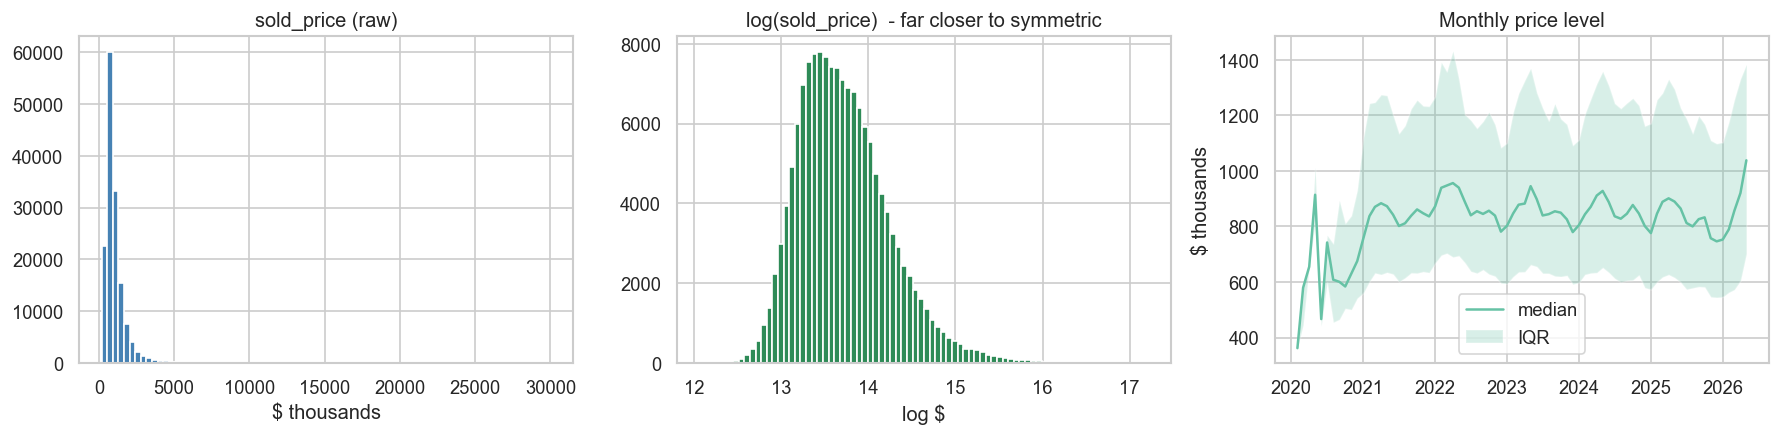

skewness raw = 5.04,  log = 0.80


In [5]:
# Target distribution and the market over time
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(y / 1e3, bins=80, color="steelblue", edgecolor="white")
axes[0].set_title(f"{TARGET} (raw)"); axes[0].set_xlabel("$ thousands")
axes[1].hist(np.log(y), bins=80, color="seagreen", edgecolor="white")
axes[1].set_title(f"log({TARGET})  - far closer to symmetric"); axes[1].set_xlabel("log $")
mm = pd.DataFrame({"m": dl_all.dt.to_period("M").dt.to_timestamp(), "y": y}).groupby("m")["y"]
axes[2].plot(mm.median().index, mm.median() / 1e3, label="median")
axes[2].fill_between(mm.median().index, mm.quantile(.25) / 1e3, mm.quantile(.75) / 1e3, alpha=.25, label="IQR")
axes[2].set_title("Monthly price level"); axes[2].set_ylabel("$ thousands"); axes[2].legend()
plt.tight_layout(); plt.show()
print(f"skewness raw = {stats.skew(y):.2f},  log = {stats.skew(np.log(y)):.2f}")

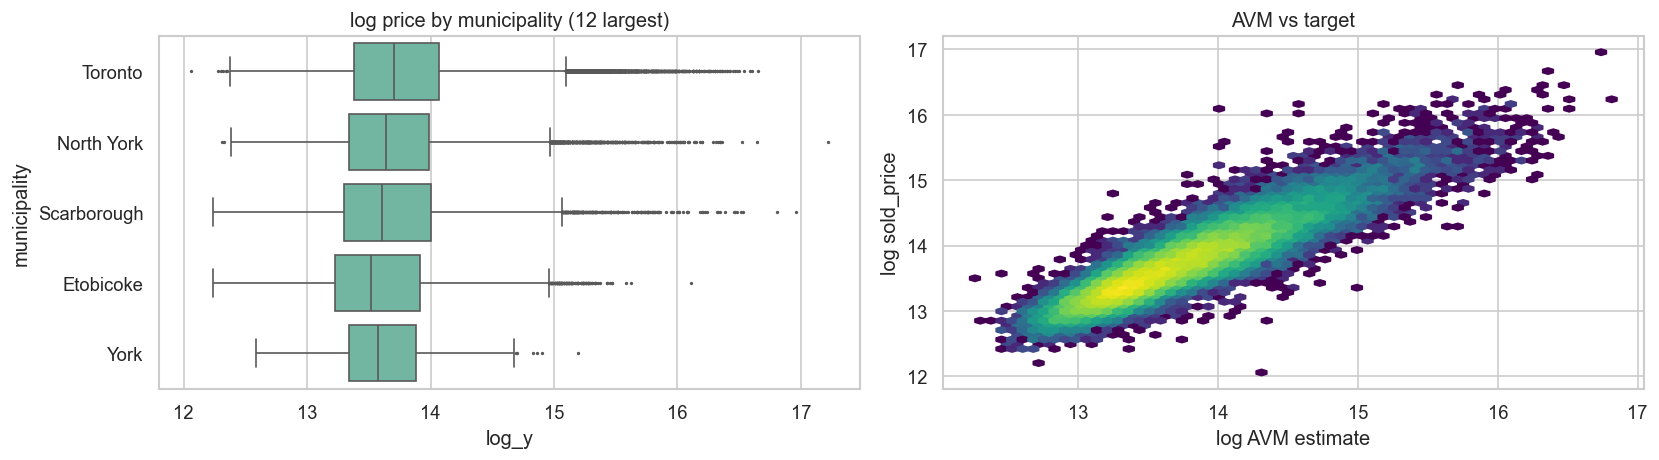

AVM available for 28.9% of rows;  as a direct prediction: MAPE = 19.32%, median APE = 15.17%  <- the benchmark any model that uses it has to beat


In [6]:
# Where does the money sit?  Price by municipality, and the AVM as a stand-alone predictor
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
order = X.groupby("municipality").size().sort_values(ascending=False).head(12).index
sns.boxplot(data=pd.DataFrame({"municipality": X["municipality"], "log_y": np.log(y)}).query("municipality in @order"),
            x="log_y", y="municipality", order=order, ax=axes[0], fliersize=1)
axes[0].set_title("log price by municipality (12 largest)")

ok = X["avm_est"].notna()
axes[1].hexbin(np.log(X.loc[ok, "avm_est"]), np.log(y[ok]), gridsize=60, bins="log", cmap="viridis")
axes[1].set_xlabel("log AVM estimate"); axes[1].set_ylabel(f"log {TARGET}"); axes[1].set_title("AVM vs target")
plt.tight_layout(); plt.show()

ape_avm = (np.abs(X.loc[ok, "avm_est"] - y[ok]) / y[ok])
print(f"AVM available for {ok.mean():.1%} of rows;  as a direct prediction: MAPE = {ape_avm.mean():.2%}, "
      f"median APE = {ape_avm.median():.2%}  <- the benchmark any model that uses it has to beat")

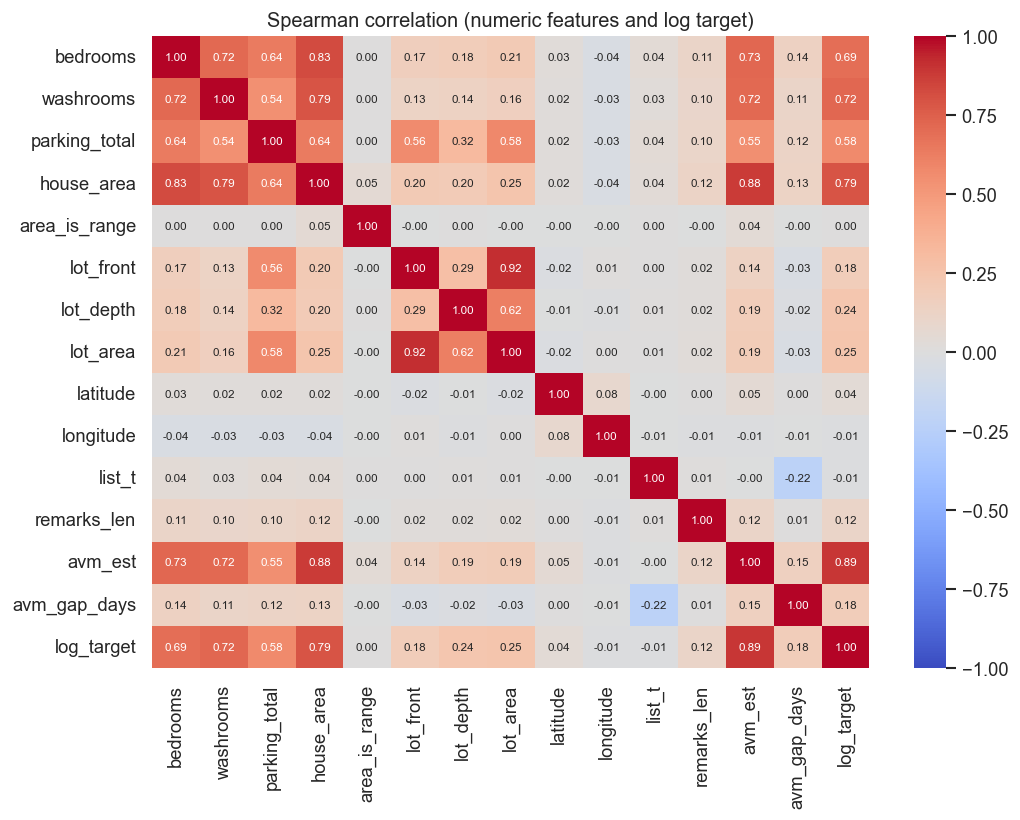

Variance inflation factors (VIF > 10 = strongly collinear):
lot_area         23.9
lot_front        16.7
lot_depth         4.9
house_area        3.6
washrooms         2.9
bedrooms          2.6
parking_total     2.0
avm_est           1.2
remarks_len       1.0
avm_gap_days      1.0
latitude          1.0
longitude         1.0
list_t            1.0


In [7]:
# Correlation structure + multicollinearity (matters for the linear models and for reading the ANOVA)
num_for_corr = X[NUM_COLS].copy()
num_for_corr["log_target"] = np.log(y)
corr = num_for_corr.corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, annot_kws={"size": 7}, ax=ax)
ax.set_title("Spearman correlation (numeric features and log target)")
plt.tight_layout(); plt.show()

vif_in = X[NUM_COLS].drop(columns=["area_is_range"]).sample(min(20000, len(X)), random_state=SEED)
vif_in = vif_in.fillna(vif_in.median())
vif_in = (vif_in - vif_in.mean()) / vif_in.std().replace(0, 1)
vif_in["const"] = 1.0
vif = pd.Series([variance_inflation_factor(vif_in.values, i) for i in range(vif_in.shape[1] - 1)],
                index=vif_in.columns[:-1]).sort_values(ascending=False)
print("Variance inflation factors (VIF > 10 = strongly collinear):"); print(vif.round(1).to_string())

## `remarks_len`: what does the length of the description tell us?
The remarks are written by a language model, so the wording carries no signal – but the **length** may reflect how much information the generator was handed about the property. Three things to establish:

1. Is there a marginal relationship between length and price, and is it non-linear?
2. Which spline family describes it best (non-smoothing vs. smoothing, cubic and higher degrees)?
3. Does it add anything **beyond** the other columns? (A marginal relationship can be pure confounding with house size – this is tested later with an ablation and a residual analysis.)

In [8]:
cv = KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)     # one splitter, used for every model in this notebook
FOLD_ID = np.zeros(len(X), dtype=int)
for k, (_, te_idx) in enumerate(cv.split(X)):
    FOLD_ID[te_idx] = k

rl = X["remarks_len"]
print(rl.describe().round(1).to_string())
print(f"\nShare of rows inside the expected range {REMARKS_RANGE}: {rl.between(*REMARKS_RANGE).mean():.1%}")

# does the length track how much property information there is?
rho_rows = []
for col in ["house_area", "bedrooms", "washrooms", "lot_area", "parking_total", "avm_est", "list_t"]:
    ok = X[col].notna()
    rho_rows.append((col, stats.spearmanr(rl[ok], X.loc[ok, col])[0]))
rho_rows.append(("log(target)", stats.spearmanr(rl, np.log(y))[0]))
print("\nSpearman correlation of remarks_len with:")
print(pd.DataFrame(rho_rows, columns=["variable", "rho"]).round(3).to_string(index=False))
print("\nMean remarks_len by house type:")
print(X.groupby("house_type_name")["remarks_len"].agg(["mean", "std", "size"]).round(1).to_string())

count    150000.0
mean        382.0
std          79.5
min         203.0
25%         323.0
50%         369.0
75%         427.0
max         819.0

Share of rows inside the expected range (200, 800): 100.0%

Spearman correlation of remarks_len with:
     variable   rho
   house_area 0.119
     bedrooms 0.112
    washrooms 0.100
     lot_area 0.024
parking_total 0.105
      avm_est 0.117
       list_t 0.010
  log(target) 0.115

Mean remarks_len by house type:
                     mean   std   size
house_type_name                       
Co-Op Apt           380.9  76.1    729
Condo Apt           372.8  75.8  76374
Condo Townhouse     381.0  77.5  10160
Detached            393.9  82.8  43202
Freehold Townhouse  396.9  84.8   5138
Semi-Detached       390.0  82.1  14397


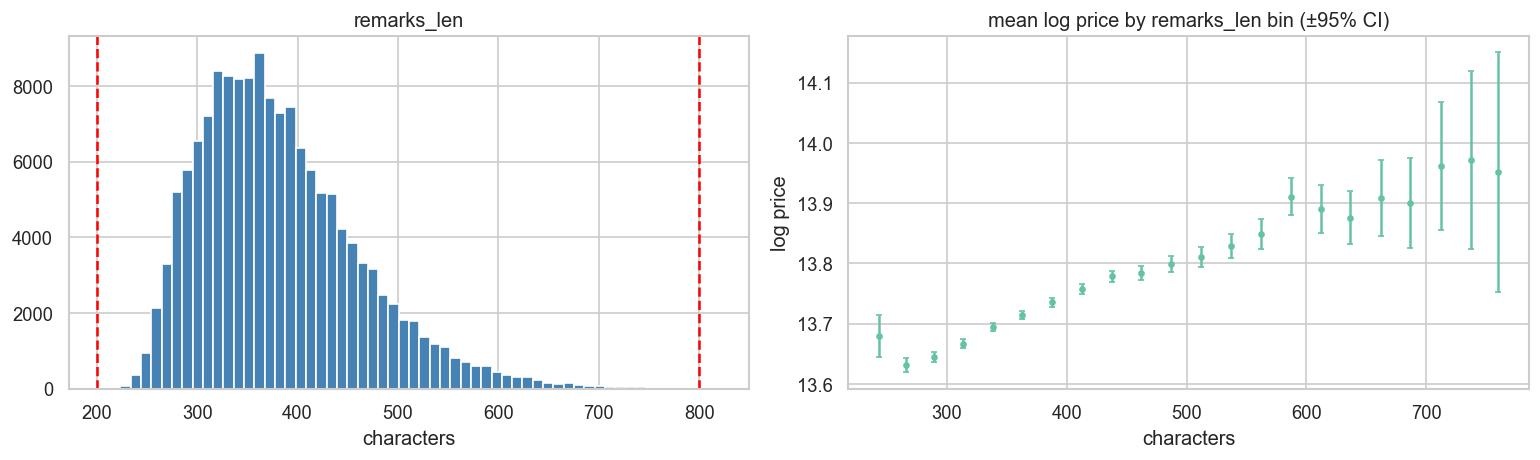

In [9]:
# Binned view of the marginal relationship
bins = pd.cut(rl, bins=np.arange(rl.min() // 25 * 25, rl.max() + 25, 25))
bm = pd.DataFrame({"bin": bins, "x": rl, "ly": np.log(y)}).groupby("bin", observed=True).agg(
        x=("x", "mean"), m=("ly", "mean"), se=("ly", lambda v: v.std() / np.sqrt(len(v))), n=("ly", "size"))
bm = bm[bm["n"] >= 30]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(rl, bins=60, color="steelblue", edgecolor="white")
for v in REMARKS_RANGE: axes[0].axvline(v, color="red", ls="--")
axes[0].set_title("remarks_len"); axes[0].set_xlabel("characters")
axes[1].errorbar(bm["x"], bm["m"], yerr=1.96 * bm["se"], fmt="o", ms=3, capsize=2)
axes[1].set_title("mean log price by remarks_len bin (±95% CI)"); axes[1].set_xlabel("characters"); axes[1].set_ylabel("log price")
plt.tight_layout(); plt.show()

### Univariate spline comparison: `log(price) ~ f(remarks_len)`
Families compared with 5-fold CV (RMSE on the log scale – smaller is better):

* **Non-smoothing (regression splines)** – B-splines fitted by plain least squares, degree 3 (cubic), 4 and 5, several knot counts, knots either at quantiles or evenly spread over the expected `[200, 800]` range; plus natural cubic splines (linear tails).
* **Smoothing splines** – a true cubic smoothing spline (scipy, λ by GCV and over a grid) and penalised B-splines / P-splines (pyGAM) of degree 3, 4, 5 with a CV-selected penalty λ.
* A straight line and a constant as reference.

Choosing λ on the same folds that are reported is slightly optimistic, but with one tuning parameter and >100k rows the effect is negligible.

In [10]:
class SmoothingSplineReg(BaseEstimator, RegressorMixin):
    """Cubic smoothing spline (scipy). Duplicated x are averaged and weighted by their count. lam=None -> GCV."""
    def __init__(self, lam=None):
        self.lam = lam
    def fit(self, X, y):
        x = np.asarray(X, dtype=float).ravel()
        g = pd.DataFrame({"x": x, "y": np.asarray(y)}).groupby("x")["y"].agg(["mean", "size"]).reset_index()
        self.lo_, self.hi_ = g["x"].min(), g["x"].max()
        xs = (g["x"].values - self.lo_) / (self.hi_ - self.lo_)
        self.spl_ = make_smoothing_spline(xs, g["mean"].values, w=g["size"].values / g["size"].mean(), lam=self.lam)
        return self
    def predict(self, X):
        x = np.clip(np.asarray(X, dtype=float).ravel(), self.lo_, self.hi_)
        return self.spl_((x - self.lo_) / (self.hi_ - self.lo_))

class NaturalCubic(BaseEstimator, TransformerMixin):
    """Natural cubic regression spline basis (patsy cr) with df degrees of freedom; clipped to the training range."""
    def __init__(self, df=6):
        self.df = df
    def fit(self, X, y=None):
        x = np.asarray(X, dtype=float).ravel()
        self.lo_, self.hi_ = x.min(), x.max()
        self.di_ = patsy.dmatrix(f"cr(x, df={self.df}) - 1", {"x": x}, return_type="matrix").design_info
        return self
    def transform(self, X):
        x = np.clip(np.asarray(X, dtype=float).ravel(), self.lo_, self.hi_)
        return np.asarray(patsy.build_design_matrices([self.di_], {"x": x})[0])

class UniGAM(BaseEstimator, RegressorMixin):
    """One-dimensional penalised B-spline (P-spline) of chosen degree via pyGAM."""
    def __init__(self, spline_order=3, n_splines=20, lam=1.0):
        self.spline_order, self.n_splines, self.lam = spline_order, n_splines, lam
    def fit(self, X, y):
        x = np.asarray(X, dtype=float).reshape(-1, 1)
        self.lo_, self.hi_ = x.min(), x.max()
        self.g_ = LinearGAM(s(0, n_splines=self.n_splines, spline_order=self.spline_order, lam=self.lam)).fit(x, np.asarray(y))
        return self
    def predict(self, X):
        return self.g_.predict(np.clip(np.asarray(X, dtype=float).reshape(-1, 1), self.lo_, self.hi_))

x_rl = X[["remarks_len"]].values
y_log = np.log(y.values)

def uni_cv(est, xr=None, yl=None):
    xr = x_rl if xr is None else xr
    yl = y_log if yl is None else yl
    rm, r2, tr2 = [], [], []
    for tr, te_ in cv.split(xr):
        m = clone(est).fit(xr[tr], yl[tr])
        p, ptr = m.predict(xr[te_]), m.predict(xr[tr])
        rm.append(np.sqrt(np.mean((yl[te_] - p) ** 2)))
        r2.append(1 - np.sum((yl[te_] - p) ** 2) / np.sum((yl[te_] - yl[te_].mean()) ** 2))
        tr2.append(1 - np.sum((yl[tr] - ptr) ** 2) / np.sum((yl[tr] - yl[tr].mean()) ** 2))
    return dict(cv_rmse=np.mean(rm), cv_r2=np.mean(r2), train_r2=np.mean(tr2))

rows, fitted_specs = [], {}
def add(family, degree, setting, est):
    t0 = time(); r = uni_cv(est)
    rows.append(dict(family=family, degree=degree, setting=setting, **r, secs=time() - t0))
    fitted_specs[(family, degree, setting)] = est

add("reference", 0, "constant", DummyRegressor())
add("reference", 1, "straight line", LinearRegression())

knot_counts = [4, 6, 8] if FAST_MODE else [4, 6, 8, 12, 16]
for deg in [3, 4, 5]:
    for k in knot_counts:
        add("regression spline (quantile knots)", deg, f"{k} knots",
            make_pipeline(SplineTransformer(n_knots=k, degree=deg, knots="quantile", extrapolation="constant", include_bias=False), LinearRegression()))
        add("regression spline (uniform knots on range)", deg, f"{k} knots",
            make_pipeline(SplineTransformer(degree=deg, knots=np.linspace(*REMARKS_RANGE, k).reshape(-1, 1), extrapolation="constant", include_bias=False), LinearRegression()))
for d_f in ([4, 6] if FAST_MODE else [4, 6, 8, 12]):
    add("natural cubic spline", 3, f"df={d_f}", make_pipeline(NaturalCubic(df=d_f), LinearRegression()))

add("smoothing spline (scipy, GCV)", 3, "lambda by GCV", SmoothingSplineReg(lam=None))
for lam in np.logspace(-8, -1, 4 if FAST_MODE else 8):
    add("smoothing spline (scipy)", 3, f"lam={lam:.0e}", SmoothingSplineReg(lam=lam))
for deg in [3, 4, 5]:
    for lam in ([1, 100] if FAST_MODE else [0.1, 1, 10, 100, 1000]):
        add("P-spline (pyGAM)", deg, f"20 basis, lam={lam:g}", UniGAM(spline_order=deg, n_splines=20, lam=lam))

uni = pd.DataFrame(rows)
uni["gap_r2"] = uni["train_r2"] - uni["cv_r2"]
best_per_family = uni.sort_values("cv_rmse").groupby(["family", "degree"], as_index=False).first().sort_values("cv_rmse")
display(best_per_family[["family", "degree", "setting", "cv_rmse", "cv_r2", "train_r2", "gap_r2"]].round(5).reset_index(drop=True))

,family,degree,setting,cv_rmse,cv_r2,train_r2,gap_r2
0,regression spline (uniform knots on range),3,8 knots,0.52183,0.01312,0.01328,0.00016
1,regression spline (uniform knots on range),5,8 knots,0.52183,0.01311,0.01330,0.00019
2,regression spline (quantile knots),3,8 knots,0.52183,0.01311,0.01326,0.00015
3,regression spline (quantile knots),5,4 knots,0.52183,0.01310,0.01321,0.00012
4,regression spline (quantile knots),4,8 knots,0.52183,0.01310,0.01325,0.00016
5,P-spline (pyGAM),3,"20 basis, lam=10",0.52184,0.01308,0.01334,0.00025
6,P-spline (pyGAM),5,"20 basis, lam=10",0.52184,0.01308,0.01330,0.00022
7,P-spline (pyGAM),4,"20 basis, lam=10",0.52184,0.01308,0.01331,0.00023
8,regression spline (uniform knots on range),4,6 knots,0.52184,0.01308,0.01323,0.00016
9,natural cubic spline,3,df=12,0.52184,0.01307,0.01328,0.00022


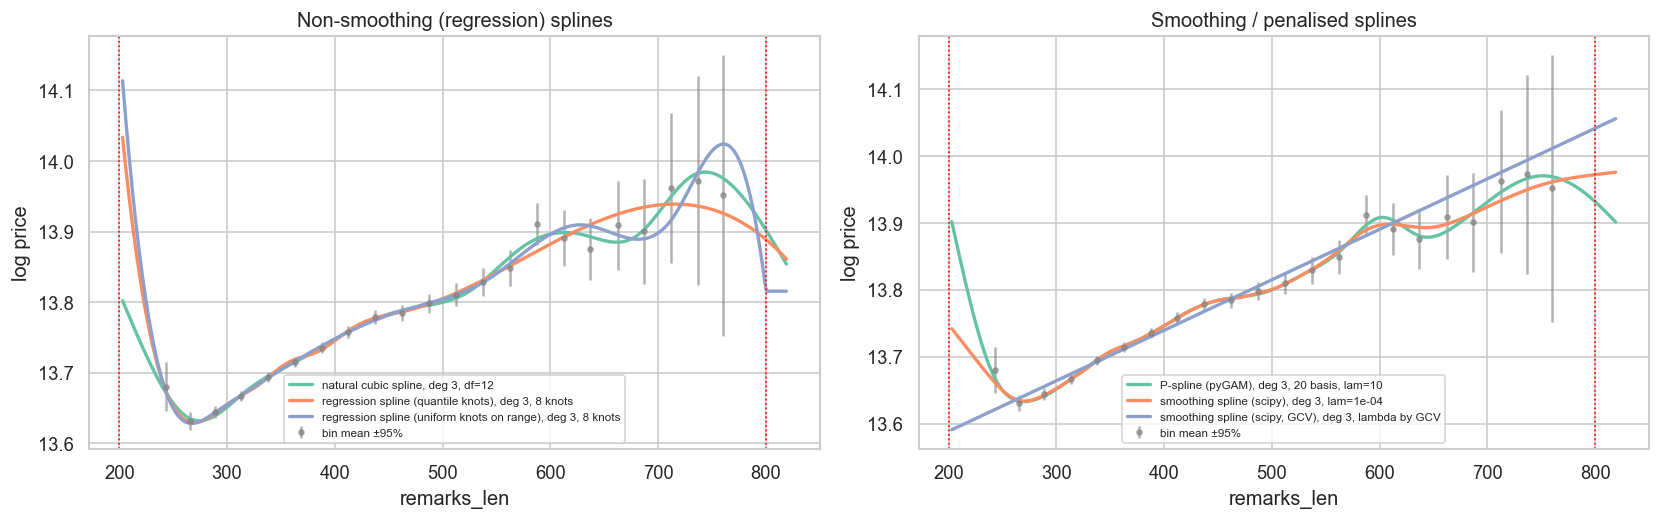

Best non-smoothing spline: degree 3, 8 knots  -> this basis is carried into the multivariate linear models below


In [11]:
# The fitted curves of the best representative of each family over the binned data
grid = np.linspace(rl.min(), rl.max(), 400).reshape(-1, 1)
show = (best_per_family[best_per_family["family"] != "reference"]
        .sort_values("cv_rmse").groupby("family", as_index=False).first())
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, subset, title in [(axes[0], show[~show["family"].str.contains("smoothing|P-spline")], "Non-smoothing (regression) splines"),
                          (axes[1], show[show["family"].str.contains("smoothing|P-spline")], "Smoothing / penalised splines")]:
    ax.errorbar(bm["x"], bm["m"], yerr=1.96 * bm["se"], fmt="o", ms=3, color="grey", alpha=.6, label="bin mean ±95%")
    for _, r in subset.iterrows():
        mdl = clone(fitted_specs[(r["family"], r["degree"], r["setting"])]).fit(x_rl, y_log)
        ax.plot(grid, mdl.predict(grid), lw=2, label=f"{r['family']}, deg {r['degree']}, {r['setting']}")
    for v in REMARKS_RANGE: ax.axvline(v, color="red", ls=":", lw=1)
    ax.set_title(title); ax.set_xlabel("remarks_len"); ax.set_ylabel("log price"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

nonsmooth = best_per_family[best_per_family["family"].str.contains("regression spline")].iloc[0]
REMARKS_SPLINE = dict(degree=int(nonsmooth["degree"]), n_knots=int(nonsmooth["setting"].split()[0]))
print(f"Best non-smoothing spline: degree {REMARKS_SPLINE['degree']}, {REMARKS_SPLINE['n_knots']} knots  "
      f"-> this basis is carried into the multivariate linear models below")

**How to read this:** a large gap between `train_r2` and `cv_r2` for the unpenalised splines means too many knots/too high a degree; the smoothing splines should be flat in λ near their optimum. If every row sits close to the straight line, the relationship is essentially linear and the extra flexibility is not buying anything. Remember this is the *marginal* relationship – the confounding question is answered after the main models.

## ANOVA on all predictors
A Type II ANOVA on `log(price)` with every predictor in the model at once: for each predictor (all its dummy columns together) it tests *"does this predictor still explain variance once everything else is in the model?"* – the multivariate counterpart of the univariate F-tests used for feature selection in the cancer notebook.

Two practical notes:

* With 150,000 rows **almost every p-value will be ≈ 0**, so the ranking is done on effect size: *partial η²* = SS(term) / (SS(term) + SS(residual)) and ΔR² = the share of total variance lost when the term is dropped.
* `community` is nested in `municipality` (and `latitude`/`longitude` overlap with both). Their individual rows can look small even though the *location block* matters a lot – the joint row at the bottom answers that question.

The tables are computed from one Gram matrix (X′X) rather than by refitting a 400-column OLS once per term, which keeps this cell fast. The next cells check it against `statsmodels.anova_lm(typ=2)` on a subsample.

In [12]:
# ---------- ANOVA design (inference only -> imputing/scaling on the full data is fine here) ----------
an = X.copy()
an["log_y"] = np.log(y.values)
num_an = [c for c in NUM_COLS if an[c].std() > 0]
flag_cols, seen_flags = {}, set()
for c in num_an:
    if an[c].isna().any():
        key = an[c].isna().values.tobytes()                   # lot_front / lot_depth / lot_area are missing for the same rows -> one flag
        if key not in seen_flags:
            seen_flags.add(key)
            an[c + "_na"] = an[c].isna().astype(int)          # missingness is a predictor too (e.g. condos have no lot)
            flag_cols[c] = c + "_na"
        an[c] = an[c].fillna(an[c].median())
for c in num_an:
    an[c] = (an[c] - an[c].mean()) / an[c].std()            # z-scores keep X'X well conditioned
min_comm = MIN_COMMUNITY_N or max(30, int(0.001 * len(an)))
vc = an["community"].value_counts()
pooled = an["community"].map(vc) < min_comm
an["community"] = np.where(pooled, "Other", an["community"])
print(f"community: {len(vc)} levels, {(vc >= min_comm).sum()} kept (>= {min_comm} rows), {pooled.mean():.1%} of rows pooled into 'Other'")

cat_an  = CAT_LOW + CAT_HIGH
formula = "log_y ~ " + " + ".join(num_an + [f"C({c})" for c in cat_an] + list(flag_cols.values()))
print(f"{len(num_an)} numeric + {len(cat_an)} categorical predictors; communities after pooling: {an['community'].nunique()}")

def term_group(name):
    m = re.fullmatch(r"C\((.+)\)", name)
    if m: return m.group(1)
    return name[:-3] if name.endswith("_na") else name

def _rss(ctx, cols):
    cols = np.asarray(cols)
    Gs, cs = ctx["G"][np.ix_(cols, cols)], ctx["c"][cols]
    beta = np.linalg.lstsq(Gs, cs, rcond=1e-10)[0]
    rank = np.linalg.matrix_rank(Gs, tol=1e-9 * np.linalg.norm(Gs, 2), hermitian=True)
    return ctx["tss"] - cs @ beta, int(rank)

def anova_type2(frame, formula, merge_flags=True, joint=None):
    """Type II ANOVA for a main-effects model = drop-one-term F tests (rank-aware, from the Gram matrix)."""
    y_, X_ = patsy.dmatrices(formula, frame, return_type="matrix")
    Xm, ym = np.asarray(X_), np.asarray(y_).ravel()
    ym = ym - ym.mean()
    ctx = dict(X=Xm, y=ym, G=Xm.T @ Xm, c=Xm.T @ ym, tss=float(ym @ ym), n=len(ym))
    gfun = term_group if merge_flags else (lambda n: n)
    groups = {}
    for term, sl in X_.design_info.term_slices.items():
        if term.name() != "Intercept":
            groups.setdefault(gfun(term.name()), []).extend(range(sl.start, sl.stop))
    allc = np.arange(Xm.shape[1])
    rss_f, rank_f = _rss(ctx, allc)
    ctx.update(rss_f=rss_f, rank_f=rank_f)
    mse = rss_f / (ctx["n"] - rank_f)
    def one(name, cols, is_joint=False):
        rss_r, rank_r = _rss(ctx, np.setdiff1d(allc, cols))
        df, ss = rank_f - rank_r, rss_r - rss_f
        F = (ss / df) / mse if df > 0 else np.nan
        return dict(term=name, joint=is_joint, df=df, ss=ss, F=F, p=stats.f.sf(F, df, ctx["n"] - rank_f) if df > 0 else np.nan,
                    eta2_partial=ss / (ss + rss_f), delta_R2=ss / ctx["tss"])
    rows = [one(g, cols) for g, cols in groups.items()]
    for jn, members in (joint or {}).items():
        rows.append(one(jn, sorted(set(i for m in members for i in groups[m])), True))
    tab = pd.DataFrame(rows).sort_values(["joint", "eta2_partial"], ascending=[True, False]).reset_index(drop=True)
    ctx["R2"] = 1 - rss_f / ctx["tss"]
    return tab, ctx

t0 = time()
anova_tab, anova_ctx = anova_type2(an, formula, joint={"LOCATION BLOCK (municipality+community+lat+lon)": ["municipality", "community", "latitude", "longitude"]})
print(f"ANOVA done in {time() - t0:.1f}s;  full-model R2 on log price = {anova_ctx['R2']:.4f}, rank = {anova_ctx['rank_f']}, n = {anova_ctx['n']:,}")

community: 145 levels, 145 kept (>= 150 rows), 0.0% of rows pooled into 'Other'
14 numeric + 6 categorical predictors; communities after pooling: 145
ANOVA done in 2.6s;  full-model R2 on log price = 0.8463, rank = 198, n = 150,000


,term,joint,df,ss,F,p,eta2_partial,delta_R2
0,community,False,140,5283.5,888.7,0.00e+00,0.45372,0.12765
1,washrooms,False,1,769.2,18113.3,0.00e+00,0.10787,0.01858
2,house_area,False,1,596.2,14038.9,0.00e+00,0.08569,0.01440
3,list_t,False,1,132.2,3112.8,0.00e+00,0.02036,0.00319
4,parking_total,False,1,114.2,2688.4,0.00e+00,0.01763,0.00276
5,bedrooms,False,1,80.0,1884.2,0.00e+00,0.01242,0.00193
6,house_style,False,15,70.5,110.7,0.00e+00,0.01096,0.00170
7,list_month,False,11,62.9,134.6,1.91e-309,0.00979,0.00152
8,house_type_name,False,4,50.2,295.6,1.02e-253,0.00783,0.00121
9,avm_est,False,2,16.0,188.1,2.52e-82,0.00251,0.00039


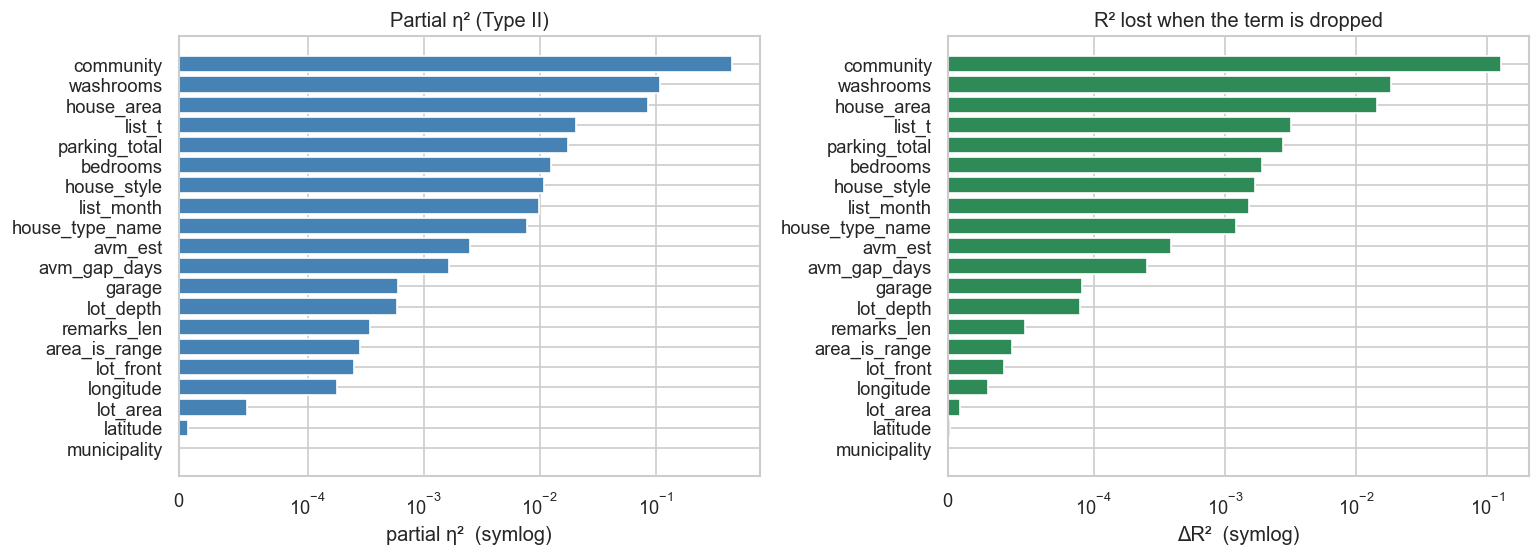

In [13]:
show = anova_tab.copy()
show["p"] = show["p"].map(lambda v: "aliased" if pd.isna(v) else f"{v:.2e}")
show["F"] = show["F"].round(1)
show["eta2_partial"] = show["eta2_partial"].round(5); show["delta_R2"] = show["delta_R2"].round(5); show["ss"] = show["ss"].round(1)
display(show)

main = anova_tab[~anova_tab["joint"]].sort_values("eta2_partial")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].barh(main["term"], main["eta2_partial"], color="steelblue"); axes[0].set_xscale("symlog", linthresh=1e-4)
axes[0].set_title("Partial η² (Type II)"); axes[0].set_xlabel("partial η²  (symlog)")
axes[1].barh(main["term"], main["delta_R2"], color="seagreen"); axes[1].set_xscale("symlog", linthresh=1e-4)
axes[1].set_title("R² lost when the term is dropped"); axes[1].set_xlabel("ΔR²  (symlog)")
plt.tight_layout(); plt.show()

In [14]:
# Sanity check against statsmodels.anova_lm(typ=2) on a 6,000-row subsample.
# (Only numeric predictors + municipality: statsmodels' own routine fails on exactly collinear dummy sets such as house_type vs house_style.)
sub = an.sample(min(6000, len(an)), random_state=SEED)
formula_chk = "log_y ~ " + " + ".join(num_an + ["C(municipality)"])
try:
    mine, _ = anova_type2(sub, formula_chk, merge_flags=False)
    ref = sm.stats.anova_lm(smf.ols(formula_chk, sub).fit(), typ=2)
    cmp = mine.set_index("term").join(ref[["F"]].rename(columns={"F": "F_statsmodels"}), how="inner").dropna(subset=["F", "F_statsmodels"])
    rel = (cmp["F"] - cmp["F_statsmodels"]).abs() / cmp["F_statsmodels"].abs().clip(lower=1e-9)
    print(f"Compared {len(cmp)} terms: max relative difference of F = {rel.max():.2e}  (should be ~1e-6 or smaller)")
except Exception as e:
    print("Cross-check skipped:", repr(e)[:200])

Compared 15 terms: max relative difference of F = 3.26e-11  (should be ~1e-6 or smaller)


### Is the spline on `remarks_len` worth it once everything else is in the model?
Nested F-tests against the model that has `remarks_len` as a straight line (an ANOVA between nested models – the classical way to test non-linearity).

In [15]:
def nested_basis_test(ctx, basis):
    B = (basis - basis.mean(0)) / np.where(basis.std(0) > 0, basis.std(0), 1)
    XtB = ctx["X"].T @ B
    Ga = np.block([[ctx["G"], XtB], [XtB.T, B.T @ B]])
    ca = np.r_[ctx["c"], B.T @ ctx["y"]]
    beta = np.linalg.lstsq(Ga, ca, rcond=1e-10)[0]
    rank = int(np.linalg.matrix_rank(Ga, tol=1e-9 * np.linalg.norm(Ga, 2), hermitian=True))
    rss1 = ctx["tss"] - ca @ beta
    d = rank - ctx["rank_f"]
    F = ((ctx["rss_f"] - rss1) / d) / (rss1 / (ctx["n"] - rank))
    return dict(extra_df=d, F=F, p=stats.f.sf(F, d, ctx["n"] - rank), delta_R2=(ctx["rss_f"] - rss1) / ctx["tss"])

rl_raw = X[["remarks_len"]].values
rows = []
for deg in [3, 4, 5]:
    for k in sorted({4, REMARKS_SPLINE["n_knots"], 8}):
        sp = SplineTransformer(n_knots=k, degree=deg, knots="quantile", extrapolation="constant", include_bias=False).fit_transform(rl_raw)
        rows.append(dict(alternative=f"B-spline degree {deg}, {k} knots", **nested_basis_test(anova_ctx, sp)))
nest = pd.DataFrame(rows)
nest["p"] = nest["p"].map(lambda v: f"{v:.2e}")
print("H0: remarks_len acts linearly  vs  H1: smooth non-linear function (all other predictors in the model)")
display(nest.round(5))

H0: remarks_len acts linearly  vs  H1: smooth non-linear function (all other predictors in the model)


,alternative,extra_df,F,p,delta_R2
0,"B-spline degree 3, 4 knots",4,3.33572,9.72e-03,0.00001
1,"B-spline degree 3, 8 knots",8,2.34387,1.63e-02,0.00002
2,"B-spline degree 4, 4 knots",5,2.54563,2.61e-02,0.00001
3,"B-spline degree 4, 8 knots",9,1.93058,4.32e-02,0.00002
4,"B-spline degree 5, 4 knots",6,2.33565,2.95e-02,0.00001
5,"B-spline degree 5, 8 knots",10,1.64926,8.64e-02,0.00002


### Your ANOVA-based input → which predictors go into the log regression
The table above is the evidence; the **decision is yours**. Fill `ANOVA_KEEP` with the predictors you want in the log regression (use the names in the `term` column). If it is left as `None`, the notebook auto-selects every predictor with `p < 0.01` **and** partial η² ≥ `ETA2_CUT`, so the rest of the notebook runs either way.

In [16]:
# ===================================================================================
#  >>>  YOUR ANOVA-BASED INPUT  <<<
#  e.g. ANOVA_KEEP = ["house_area", "bedrooms", "washrooms", "house_type_name", "municipality",
#                     "community", "latitude", "longitude", "list_t", "avm_est", "remarks_len"]
ANOVA_KEEP = None
ETA2_CUT   = 0.002       # only used when ANOVA_KEEP is None
# ===================================================================================
main_terms = anova_tab[~anova_tab["joint"]]
auto_keep  = main_terms.loc[(main_terms["p"] < 0.01) & (main_terms["eta2_partial"] >= ETA2_CUT), "term"].tolist()
KEEP = auto_keep if ANOVA_KEEP is None else list(ANOVA_KEEP)
unknown = [c for c in KEEP if c not in ALL_FEATS]
assert not unknown, f"Not predictor columns: {unknown}.  Valid names: {ALL_FEATS}"
print("Source  :", "auto (p<0.01 and partial eta2 >= %.4f)" % ETA2_CUT if ANOVA_KEEP is None else "your ANOVA_KEEP list")
print(f"Kept    ({len(KEEP)}): {KEEP}")
print(f"Dropped ({len(ALL_FEATS) - len(KEEP)}): {[c for c in ALL_FEATS if c not in KEEP]}")

Source  : auto (p<0.01 and partial eta2 >= 0.0020)
Kept    (10): ['community', 'washrooms', 'house_area', 'list_t', 'parking_total', 'bedrooms', 'house_style', 'list_month', 'house_type_name', 'avm_est']
Dropped (10): ['area_is_range', 'lot_front', 'lot_depth', 'lot_area', 'latitude', 'longitude', 'remarks_len', 'avm_gap_days', 'garage', 'municipality']


## Data Preprocessing and CV protocol
As in the cancer notebook, **every fitted step lives inside the pipeline**, so it is re-fitted on the training part of each fold:

* numeric: median imputation (+ missing-indicator columns, e.g. condos have no lot) → scaling
* low-cardinality categoricals: one-hot (rare levels pooled) for linear/distance models, ordinal codes for trees
* `community` (hundreds of levels): `TargetEncoder`, which cross-fits internally so it cannot leak the target
* price models are trained on `log(price)` and predictions are transformed back, so **all metrics below are in dollars / percent**

Metrics: RMSE and MAE in $, R², **MAPE** and median APE (relative error – the natural scale for house prices) and the share of listings predicted within ±10%.

In [17]:
CONT = ["house_area", "lot_front", "lot_depth", "lot_area", "latitude", "longitude", "list_t", "remarks_len", "avm_est", "avm_gap_days"]
LOG_COLS = ["house_area", "lot_front", "lot_depth", "lot_area", "avm_est"]

def _sel(cols, keep):
    return list(cols) if keep is None else [c for c in cols if c in keep]

def make_prep(kind, keep=None, remarks_spline=None, log_cols=(), degree=3, n_knots=7):
    """kind: 'onehot' (linear models) | 'tree' (ordinal codes) | 'te' (compact, all categoricals target-encoded)
             | 'spline' (additive spline basis for the continuous predictors + one-hot)"""
    num, cl, ch = _sel(NUM_COLS, keep), _sel(CAT_LOW, keep), _sel(CAT_HIGH, keep)
    log_cols = [c for c in log_cols if c in num]
    scale = [] if kind == "tree" else [("sc", StandardScaler())]
    tfs = []
    if remarks_spline and "remarks_len" in num:
        num = [c for c in num if c != "remarks_len"]
        tfs.append(("remarks_spline", Pipeline([("sp", SplineTransformer(n_knots=remarks_spline["n_knots"], degree=remarks_spline["degree"],
                    knots="quantile", extrapolation="constant", include_bias=False)), ("sc", StandardScaler())]), ["remarks_len"]))
    if log_cols:
        num = [c for c in num if c not in log_cols]
        tfs.append(("log_num", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                   ("imp", SimpleImputer(strategy="median", add_indicator=True))] + scale), log_cols))
    if kind == "spline":
        cont = [c for c in num if c in CONT]; other = [c for c in num if c not in CONT]
        if cont:
            tfs.append(("cont_spline", Pipeline([("imp", SimpleImputer(strategy="median")),
                       ("sp", SplineTransformer(n_knots=n_knots, degree=degree, knots="quantile", extrapolation="constant")),
                       ("sc", StandardScaler())]), cont))
        if other:
            tfs.append(("other_num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), other))
        from sklearn.impute import MissingIndicator
        tfs.append(("na_flags", MissingIndicator(features="missing-only", error_on_new=False), cont + other))
    elif num:
        tfs.append(("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True))] + scale), num))
    if kind in ("onehot", "spline"):
        if cl: tfs.append(("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.005, sparse_output=False), cl))
        if ch: tfs.append(("hi", Pipeline([("te", TargetEncoder(random_state=SEED)), ("sc", StandardScaler())]), ch))
    elif kind == "tree":
        if cl: tfs.append(("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, min_frequency=0.005), cl))
        if ch: tfs.append(("hi", TargetEncoder(random_state=SEED), ch))
    elif kind == "te":
        if cl + ch: tfs.append(("te", Pipeline([("te", TargetEncoder(random_state=SEED)), ("sc", StandardScaler())]), cl + ch))
    return ColumnTransformer(tfs, remainder="drop", verbose_feature_names_out=False)

def wrap(est, log=True):
    return TransformedTargetRegressor(regressor=est, func=np.log, inverse_func=np.exp, check_inverse=False) if log else est

def pipe(kind, model, **prep_kw):
    return Pipeline([("prep", make_prep(kind, **prep_kw)), ("model", model)])

# quick shape check on the full pipeline
chk = make_prep("onehot").fit(X.iloc[:5000], np.log(y.iloc[:5000]))
print("onehot design matrix:", chk.transform(X.iloc[:5]).shape, "| tree:", make_prep("tree").fit(X.iloc[:5000], np.log(y.iloc[:5000])).transform(X.iloc[:5]).shape)

onehot design matrix: (5, 53) | tree: (5, 25)


In [18]:
def metrics(y_true, y_pred):
    y_pred = np.maximum(np.asarray(y_pred, dtype=float), 1.0)
    err = y_pred - y_true
    ape = np.abs(err) / y_true
    return dict(rmse=np.sqrt(np.mean(err ** 2)), mae=np.mean(np.abs(err)),
                r2=1 - np.sum(err ** 2) / np.sum((y_true - y_true.mean()) ** 2),
                mape=ape.mean(), medape=np.median(ape), within10=(ape <= 0.10).mean(),
                log_rmse=np.sqrt(np.mean((np.log(y_pred) - np.log(y_true)) ** 2)))

RESULTS, OOF, TRAINM, TIMES, EST = {}, {}, {}, {}, {}

def _fit_fold(est, Xd, yd, tr, te_):
    t0 = time()
    m = clone(est).fit(Xd.iloc[tr], yd.iloc[tr])
    p_te = m.predict(Xd.iloc[te_])
    sub = np.random.default_rng(SEED).choice(tr, size=min(10_000, len(tr)), replace=False)   # train score on a 10k subsample (cheap)
    return te_, p_te, metrics(yd.iloc[te_].values, p_te), metrics(yd.iloc[sub].values, m.predict(Xd.iloc[sub])), time() - t0

def run_cv(name, est, fold_jobs=1, verbose=True):
    """5-fold CV on all rows; stores fold metrics, out-of-fold predictions and train-subsample metrics."""
    t0 = time()
    out = Parallel(n_jobs=fold_jobs)(delayed(_fit_fold)(est, X, y, tr, te_) for tr, te_ in cv.split(X))
    oof = np.zeros(len(y))
    for te_, p, *_ in out: oof[te_] = p
    RESULTS[name] = pd.DataFrame([o[2] for o in out]); TRAINM[name] = pd.DataFrame([o[3] for o in out])
    OOF[name] = oof; TIMES[name] = time() - t0; EST[name] = est
    if verbose:
        r = RESULTS[name]
        print(f"  {name:<44} RMSE={r.rmse.mean():>10,.0f}  MAPE={r.mape.mean():6.2%}  R2={r.r2.mean():.4f}  ({TIMES[name]:.0f}s)")
    return RESULTS[name]

def leaderboard(names=None, sort="mape"):
    rows = []
    for n in (names or list(RESULTS)):
        r, t = RESULTS[n], TRAINM[n]
        rows.append(dict(model=n, rmse=r.rmse.mean(), rmse_sd=r.rmse.std(), mae=r.mae.mean(), r2=r.r2.mean(), mape=r.mape.mean(),
                         mape_sd=r.mape.std(), medape=r.medape.mean(), within10=r.within10.mean(),
                         train_mape=t.mape.mean(), time_s=TIMES[n]))
    return pd.DataFrame(rows).sort_values(sort).set_index("model")

def fmt_board(b):
    return (b.style.format({"rmse": "{:,.0f}", "rmse_sd": "{:,.0f}", "mae": "{:,.0f}", "r2": "{:.4f}", "mape": "{:.2%}", "mape_sd": "{:.2%}",
                            "medape": "{:.2%}", "within10": "{:.1%}", "train_mape": "{:.2%}", "time_s": "{:.0f}"})
            .background_gradient(subset=["mape"], cmap="YlGn_r"))

# Reference point: the external AVM used directly (no fitting at all)
ok = X["avm_est"].notna()
print("AVM used directly as the prediction (rows where it is available):",
      {k: round(float(v), 4) for k, v in metrics(y[ok].values, X.loc[ok, "avm_est"].values).items() if k in ("mape", "medape", "within10", "r2")})

AVM used directly as the prediction (rows where it is available): {'r2': 0.6929, 'mape': 0.1932, 'medape': 0.1517, 'within10': 0.3463}


### ANOVA-F feature selection, the CV way
The cancer notebook swept the number of ANOVA-selected genes `k` with a grid search. The regression analogue: `SelectKBest(f_regression)` on the encoded design matrix inside a linear log-model, `k` chosen by CV. Univariate F-tests ignore overlap between predictors (which the Type II table above handles), so this is a cross-check rather than a replacement.

In [19]:
tune_n = 3000 if FAST_MODE else 30_000
tune_idx = np.random.default_rng(SEED + 1).choice(len(X), size=min(tune_n, len(X)), replace=False)      # separate seed from the CV folds
X_tune, y_tune = X.iloc[tune_idx], y.iloc[tune_idx]

sel_model = wrap(Pipeline([("prep", make_prep("onehot")), ("sel", SelectKBest(f_regression)), ("model", LinearRegression())]))
n_enc = make_prep("onehot").fit(X_tune, np.log(y_tune)).transform(X_tune.iloc[:5]).shape[1]
grid_k = sorted({k for k in [3, 5, 8, 12, 20, 30, 50, 80, n_enc] if k <= n_enc})
gs = GridSearchCV(sel_model, {"regressor__sel__k": grid_k}, cv=KFold(5, shuffle=True, random_state=SEED),
                  scoring={"rmse": "neg_root_mean_squared_error"}, refit="rmse", return_train_score=True, n_jobs=1)
gs.fit(X_tune, y_tune)
kk = pd.DataFrame({"k": grid_k, "cv_rmse": -gs.cv_results_["mean_test_rmse"], "train_rmse": -gs.cv_results_["mean_train_rmse"]}).set_index("k")
print(kk.round(0).to_string()); print(f"\nBest k = {gs.best_params_['regressor__sel__k']} of {n_enc} encoded columns")

     cv_rmse  train_rmse
k                       
3   515391.0    514859.0
5   515391.0    514859.0
8   515493.0    514798.0
12  485116.0    484827.0
20  480867.0    478138.0
30  481746.0    478778.0
50  481626.0    478165.0
61  481693.0    478423.0

Best k = 20 of 61 encoded columns


## Model comparison (stage 1: sensible defaults, 5-fold CV on all rows)

Families, in the order you listed them, plus two reference points:

| Family | Models |
|---|---|
| Reference | mean baseline |
| Linear | OLS on raw price; OLS on log price; OLS (log) with a spline for `remarks_len` |
| Log regression (your ANOVA inputs) | log-linear and log-log, using only the predictors in `KEEP` |
| Additive | cubic / quartic / quintic spline additive models (ridge-penalised); smooth GAM (pyGAM: `s()` terms, tensor `te(lat, lon)`, `f()` factors) |
| Trees | Random forest, XGBoost, histogram gradient boosting |
| Distance | KNN on all predictors and on the ANOVA-selected ones |
| SVM | linear SVR; RBF-kernel SVR via Nyström approximation (all rows); exact RBF SVR trained on a subsample |

**A note on SVR:** exact kernel SVR is O(n²)–O(n³); on ~120k training rows per fold it would run for hours. Hence the three variants above – the exact one is *fitted* on `SVR_N` randomly chosen training rows per fold but *scored* on the full test fold, so its numbers are directly comparable.

In [20]:
SVR_N = 1500 if FAST_MODE else 12_000

class SubsampleFit(BaseEstimator, RegressorMixin):
    """Fit the wrapped estimator on at most n_max randomly chosen training rows; predict for everything."""
    def __init__(self, estimator=None, n_max=15_000, random_state=42):
        self.estimator, self.n_max, self.random_state = estimator, n_max, random_state
    def fit(self, X, y):
        idx = np.random.default_rng(self.random_state).choice(len(X), size=min(self.n_max, len(X)), replace=False)
        self.est_ = clone(self.estimator).fit(X[idx], np.asarray(y)[idx])
        return self
    def predict(self, X):
        return self.est_.predict(X)

import operator
from functools import reduce

class GAMReg(BaseEstimator, RegressorMixin):
    """Additive model with pyGAM: s() on continuous predictors, te() on latitude x longitude,
    f() on categoricals, discrete numerics (<=12 values) and missing-indicators."""
    def __init__(self, lam=1.0, n_splines=12, spline_order=3, max_levels=80, keep=None, log_cols=tuple(LOG_COLS)):
        self.lam, self.n_splines, self.spline_order, self.max_levels, self.keep, self.log_cols = lam, n_splines, spline_order, max_levels, keep, log_cols

    def _matrix(self, Xd):
        cols = []
        for c in self.cont_:
            v = Xd[c].astype(float).fillna(self.med_[c]).clip(self.lo_[c], self.hi_[c])
            cols.append(np.log1p(v).values if c in self.log_cols else v.values)
        for c in self.geo_:
            cols.append(Xd[c].astype(float).fillna(self.med_[c]).clip(self.lo_[c], self.hi_[c]).values)
        for c in self.na_:
            cols.append(Xd[c].isna().astype(int).values)
        for c in self.fac_:
            lv, oth = self.levels_[c], self.other_[c]
            cols.append(Xd[c].astype(str).map(lambda z: lv.get(z, oth)).astype(int).values)
        return np.column_stack(cols)

    def fit(self, X, y):
        Xd = pd.DataFrame(X).reset_index(drop=True)
        num, cat = _sel(NUM_COLS, self.keep), _sel(CAT_LOW + CAT_HIGH, self.keep)
        self.geo_  = [c for c in ("latitude", "longitude") if c in num]
        disc       = [c for c in num if Xd[c].nunique() <= 12 and c not in self.geo_]
        self.cont_ = [c for c in num if c not in disc and c not in self.geo_]
        self.na_   = [c for c in num if Xd[c].isna().any()]
        self.fac_  = disc + cat
        self.med_  = {c: (Xd[c].median() if Xd[c].notna().any() else 0.0) for c in self.cont_ + self.geo_}
        self.lo_   = {c: Xd[c].min() for c in self.cont_ + self.geo_}
        self.hi_   = {c: Xd[c].max() for c in self.cont_ + self.geo_}
        self.levels_, self.other_ = {}, {}
        for c in self.fac_:
            vals = Xd[c].astype(str)
            top = vals.value_counts().index[: self.max_levels]
            self.levels_[c] = {v: i for i, v in enumerate(top)}
            self.other_[c] = len(top) if (~vals.isin(top)).any() else 0   # unseen levels -> pooled level, or the most frequent one
        
        terms, i = [], 0
        for c in self.cont_:
            terms.append(s(i, n_splines=min(self.n_splines, Xd[c].nunique() - 1), spline_order=self.spline_order, lam=self.lam)); i += 1
        if len(self.geo_) == 2:
            terms.append(te(i, i + 1, n_splines=[10, 10], lam=self.lam)); i += 2
        else:
            for _ in self.geo_:
                terms.append(s(i, n_splines=self.n_splines, lam=self.lam)); i += 1
        for _ in self.na_ + self.fac_:
            terms.append(f(i, lam=self.lam)); i += 1
        self.gam_ = LinearGAM(reduce(operator.add, terms), max_iter=50).fit(self._matrix(Xd), np.asarray(y))
        return self

    def predict(self, X):
        return self.gam_.predict(self._matrix(pd.DataFrame(X).reset_index(drop=True)))

n_nys = 150 if FAST_MODE else 400
n_rf, n_xgb, n_hgb = (40, 80, 80) if FAST_MODE else (250, 600, 500)

MODELS = {
    "Mean baseline":                    wrap(pipe("onehot", DummyRegressor()), log=False),
    "OLS (raw price)":                  wrap(pipe("onehot", LinearRegression()), log=False),
    "OLS (log price)":                  wrap(pipe("onehot", LinearRegression())),
    "OLS (log) + remarks spline":       wrap(pipe("onehot", LinearRegression(), remarks_spline=REMARKS_SPLINE)),
    "Log-linear (ANOVA inputs)":        wrap(pipe("onehot", LinearRegression(), keep=KEEP)),
    "Log-log (ANOVA inputs)":           wrap(pipe("onehot", LinearRegression(), keep=KEEP, log_cols=LOG_COLS)),
    "Additive splines deg 3 (ridge)":   wrap(pipe("spline", RidgeCV(alphas=np.logspace(-2, 3, 6)), degree=3)),
    "Additive splines deg 4 (ridge)":   wrap(pipe("spline", RidgeCV(alphas=np.logspace(-2, 3, 6)), degree=4)),
    "Additive splines deg 5 (ridge)":   wrap(pipe("spline", RidgeCV(alphas=np.logspace(-2, 3, 6)), degree=5)),
    "GAM (pyGAM, smooth)":              wrap(GAMReg(lam=1.0)),
    "Random forest":                    wrap(pipe("tree", RandomForestRegressor(n_estimators=n_rf, min_samples_leaf=3, max_features=0.5, n_jobs=-1, random_state=SEED))),
    "XGBoost":                          wrap(pipe("tree", XGBRegressor(n_estimators=n_xgb, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
                                                                       tree_method="hist", n_jobs=-1, random_state=SEED))),
    "HistGradientBoosting":             wrap(pipe("tree", HistGradientBoostingRegressor(max_iter=n_hgb, learning_rate=0.08, early_stopping=True, random_state=SEED))),
    "KNN-10 (all predictors)":          wrap(pipe("te", KNeighborsRegressor(n_neighbors=10, weights="distance", n_jobs=-1))),
    "KNN-10 (ANOVA inputs)":            wrap(pipe("te", KNeighborsRegressor(n_neighbors=10, weights="distance", n_jobs=-1), keep=KEEP)),
    "Linear SVR":                       wrap(pipe("onehot", LinearSVR(C=1.0, epsilon=0.0, loss="squared_epsilon_insensitive", dual=False, max_iter=2000, random_state=SEED))),
    "SVR-RBF (Nystroem, all rows)":     wrap(Pipeline([("prep", make_prep("te")), ("nys", Nystroem(n_components=n_nys, random_state=SEED)),
                                                       ("model", LinearSVR(C=1.0, epsilon=0.0, loss="squared_epsilon_insensitive", dual=False, max_iter=2000, random_state=SEED))])),
    "SVR-RBF exact (subsample)":        wrap(pipe("te", SubsampleFit(SVR(kernel="rbf", C=10.0, epsilon=0.02), n_max=SVR_N, random_state=SEED))),
    "SVR-RBF exact (ANOVA inputs)":     wrap(pipe("te", SubsampleFit(SVR(kernel="rbf", C=10.0, epsilon=0.02), n_max=SVR_N, random_state=SEED), keep=KEEP)),
}
INTERNAL_PARALLEL = {"Random forest", "XGBoost", "HistGradientBoosting", "KNN-10 (all predictors)", "KNN-10 (ANOVA inputs)"}

print(f"Stage 1: {len(MODELS)} models, {N_SPLITS}-fold CV on {len(X):,} rows\n")
failed = {}
for name, est in MODELS.items():
    try:
        run_cv(name, est, fold_jobs=1 if name in INTERNAL_PARALLEL else -1)
    except Exception as e:                       # one failing model should not stop the notebook
        failed[name] = repr(e)[:200]; print(f"  {name:<44} FAILED: {failed[name]}")

Stage 1: 19 models, 5-fold CV on 150,000 rows

  Mean baseline                                FAILED: MemoryError((120000, 23619), dtype('int64'))
  OLS (raw price)                              FAILED: MemoryError((120000, 23657), dtype('int64'))
  OLS (log price)                              RMSE=   484,223  MAPE=19.43%  R2=0.6446  (6s)
  OLS (log) + remarks spline                   RMSE=   484,253  MAPE=19.43%  R2=0.6446  (5s)
  Log-linear (ANOVA inputs)                    RMSE=   486,271  MAPE=19.57%  R2=0.6416  (3s)
  Log-log (ANOVA inputs)                       RMSE=   455,468  MAPE=18.99%  R2=0.6857  (2s)
  Additive splines deg 3 (ridge)               RMSE=   441,332  MAPE=18.26%  R2=0.7049  (12s)
  Additive splines deg 4 (ridge)               RMSE=   439,538  MAPE=18.18%  R2=0.7073  (10s)
  Additive splines deg 5 (ridge)               RMSE=   440,194  MAPE=18.19%  R2=0.7064  (10s)
  GAM (pyGAM, smooth)                          RMSE=   387,013  MAPE=15.67%  R2=0.7730  (54s)
  Ran

  File "c:\Tools\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Tools\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Tools\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Tools\anaconda3\Lib\subprocess.py", line 1554, in _exec

  HistGradientBoosting                         RMSE=   324,584  MAPE=12.69%  R2=0.8403  (21s)
  KNN-10 (all predictors)                      RMSE=   428,060  MAPE=17.59%  R2=0.7224  (20s)
  KNN-10 (ANOVA inputs)                        RMSE=   426,544  MAPE=17.92%  R2=0.7243  (23s)
  Linear SVR                                   RMSE=   484,207  MAPE=19.42%  R2=0.6446  (4s)
  SVR-RBF (Nystroem, all rows)                 RMSE=   470,323  MAPE=18.01%  R2=0.6646  (24s)
  SVR-RBF exact (subsample)                    RMSE=   485,944  MAPE=18.74%  R2=0.6422  (76s)
  SVR-RBF exact (ANOVA inputs)                 RMSE=   482,900  MAPE=18.14%  R2=0.6463  (49s)


,rmse,rmse_sd,mae,r2,mape,mape_sd,medape,within10,train_mape,time_s
model,,,,,,,,,,
HistGradientBoosting,"324,584","9,918","153,321",0.8403,12.69%,0.12%,9.98%,50.1%,11.93%,21
XGBoost,"331,302","11,177","156,272",0.8336,12.94%,0.15%,10.17%,49.3%,12.01%,17
Random forest,"360,808","16,004","170,499",0.8028,14.12%,0.12%,11.07%,45.9%,8.16%,104
"GAM (pyGAM, smooth)","387,013","13,108","187,537",0.7730,15.67%,0.09%,12.38%,41.5%,15.57%,54
KNN-10 (all predictors),"428,060","20,085","209,450",0.7224,17.59%,0.09%,14.21%,36.5%,4.73%,20
KNN-10 (ANOVA inputs),"426,544","18,423","211,377",0.7243,17.92%,0.14%,14.23%,36.7%,9.04%,23
"SVR-RBF (Nystroem, all rows)","470,323","27,497","215,046",0.6646,18.01%,0.14%,14.08%,36.9%,17.93%,24
SVR-RBF exact (ANOVA inputs),"482,900","12,969","222,747",0.6463,18.14%,0.16%,14.05%,37.1%,14.08%,49
Additive splines deg 4 (ridge),"439,538","17,325","214,404",0.7073,18.18%,0.10%,14.39%,36.2%,18.12%,10


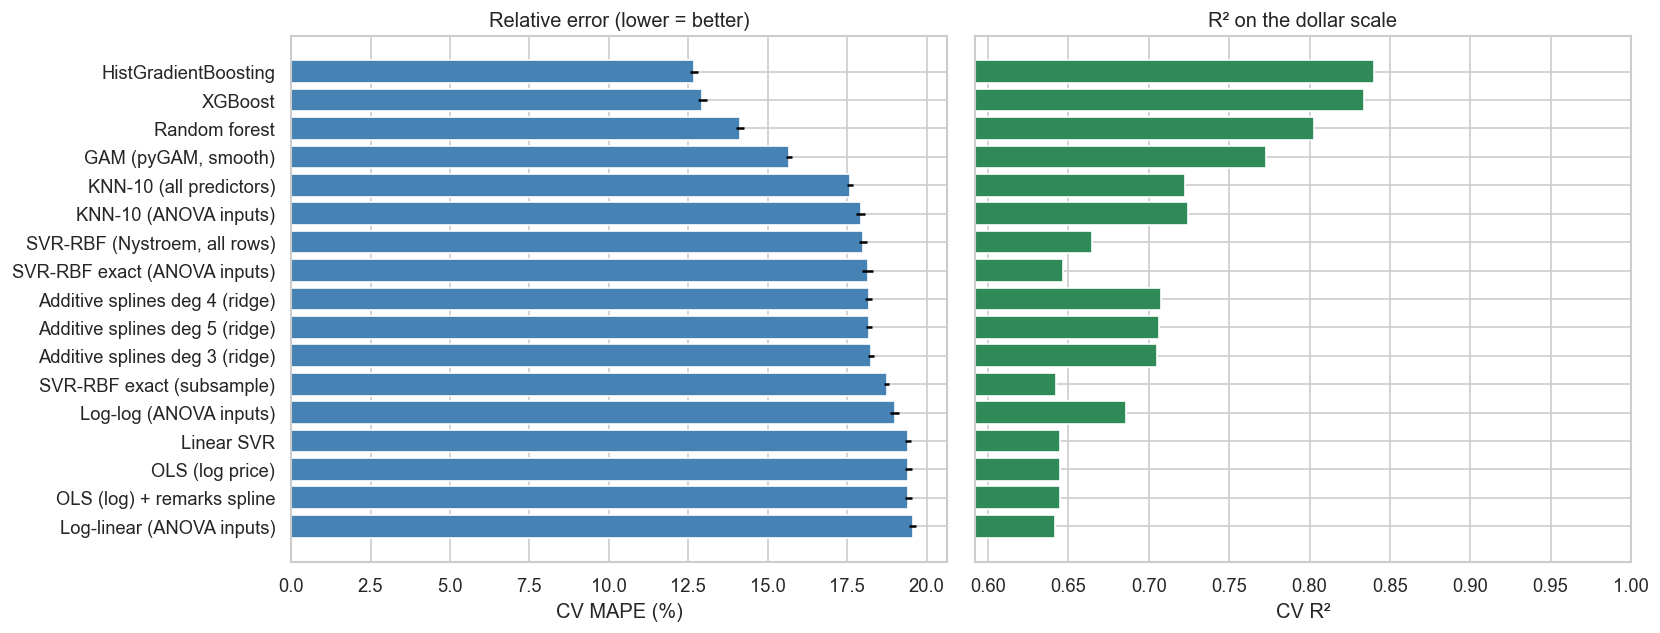

Failed models: {'Mean baseline': "MemoryError((120000, 23619), dtype('int64'))", 'OLS (raw price)': "MemoryError((120000, 23657), dtype('int64'))"}


In [21]:
board1 = leaderboard()
display(fmt_board(board1))

fig, axes = plt.subplots(1, 2, figsize=(14, max(4, 0.32 * len(board1))))
b = board1.sort_values("mape", ascending=False)
axes[0].barh(b.index, b["mape"] * 100, xerr=b["mape_sd"] * 100, color="steelblue"); axes[0].set_xlabel("CV MAPE (%)"); axes[0].set_title("Relative error (lower = better)")
axes[1].barh(b.index, b["r2"], color="seagreen"); axes[1].set_xlim(max(0, b["r2"].min() - 0.05), 1); axes[1].set_xlabel("CV R²"); axes[1].set_title("R² on the dollar scale")
axes[1].set_yticklabels([])
plt.tight_layout(); plt.show()
if failed: print("Failed models:", failed)

In [22]:
# Does the spline on remarks_len help inside the full linear model?  (same folds -> paired comparison)
a, b = RESULTS["OLS (log price)"], RESULTS["OLS (log) + remarks spline"]
d = (a["rmse"] - b["rmse"])
print(f"RMSE improvement from the remarks_len spline, per fold ($): {d.round(0).tolist()}   mean {d.mean():,.0f}  (positive = spline better)")
print(f"MAPE linear {a.mape.mean():.3%}  vs spline {b.mape.mean():.3%}")

RMSE improvement from the remarks_len spline, per fold ($): [121.0, -152.0, -16.0, 39.0, -141.0]   mean -30  (positive = spline better)
MAPE linear 19.426%  vs spline 19.428%


## Hyperparameter tuning (stage 2) and full-data CV of the tuned models (stage 3)
Same recipe as in the cancer notebook – tune the promising models – adapted to the data size:

* **Stage 2:** `RandomizedSearchCV` (selection metric = MAPE) on a 30,000-row subsample drawn with a *different seed* than the CV folds, so it stays cheap.
* **Stage 3:** the tuned settings are re-evaluated with the identical 5-fold CV on **all rows**.

Rows are re-used between stages 2 and 3, so the stage-3 numbers are marginally optimistic relative to a truly untouched test set (the tuning only chose a handful of hyperparameters from a 30k sample, so the effect is small). For the KNN and exact-SVR variants the better of "all predictors" and "ANOVA inputs" from stage 1 is tuned.

In [23]:
def best_of(a, b):
    ok_ = [n for n in (a, b) if n in RESULTS]
    return min(ok_, key=lambda n: RESULTS[n].mape.mean()) if ok_ else None

knn_name = best_of("KNN-10 (all predictors)", "KNN-10 (ANOVA inputs)")
svr_name = best_of("SVR-RBF exact (subsample)", "SVR-RBF exact (ANOVA inputs)")

n_it = (2 if FAST_MODE else None)
SPACES = {
    "Random forest": ({"regressor__model__max_features": [0.3, 0.5, 0.7, 1.0], "regressor__model__min_samples_leaf": [1, 2, 3, 5, 8],
                       "regressor__model__max_depth": [None, 20, 30]}, n_it or 6),
    "XGBoost": ({"regressor__model__n_estimators": randint(300, 1200), "regressor__model__learning_rate": loguniform(0.02, 0.15),
                 "regressor__model__max_depth": randint(4, 10), "regressor__model__subsample": uniform(0.6, 0.4),
                 "regressor__model__colsample_bytree": uniform(0.5, 0.5), "regressor__model__min_child_weight": randint(1, 20),
                 "regressor__model__reg_lambda": loguniform(0.1, 10)}, n_it or 15),
    "HistGradientBoosting": ({"regressor__model__learning_rate": loguniform(0.03, 0.2), "regressor__model__max_leaf_nodes": randint(15, 127),
                              "regressor__model__min_samples_leaf": randint(10, 100), "regressor__model__l2_regularization": loguniform(1e-3, 10),
                              "regressor__model__max_iter": [300, 600, 1000]}, n_it or 15),
    "GAM (pyGAM, smooth)": ({"regressor__lam": loguniform(0.05, 30), "regressor__n_splines": [8, 12, 20]}, n_it or 6),
    "SVR-RBF (Nystroem, all rows)": ({"regressor__nys__gamma": loguniform(0.005, 0.5), "regressor__model__C": loguniform(0.3, 30)}, n_it or 6),
}
if knn_name: SPACES[knn_name] = ({"regressor__model__n_neighbors": [5, 8, 10, 15, 20, 30], "regressor__model__weights": ["uniform", "distance"],
                                  "regressor__model__p": [1, 2]}, n_it or 8)
if svr_name: SPACES[svr_name] = ({"regressor__model__estimator__C": loguniform(1, 100), "regressor__model__estimator__epsilon": loguniform(0.005, 0.1),
                                  "regressor__model__estimator__gamma": loguniform(0.005, 0.5)}, n_it or 6)

inner_cv = KFold(3 if FAST_MODE else 5, shuffle=True, random_state=SEED)
BEST_PARAMS = {}
for name, (space, n_iter) in SPACES.items():
    if name not in RESULTS: continue
    t0 = time()
    try:
        rs = RandomizedSearchCV(clone(MODELS[name]), space, n_iter=n_iter, cv=inner_cv, scoring="neg_mean_absolute_percentage_error",
                                random_state=SEED, n_jobs=1 if name in INTERNAL_PARALLEL else -1, refit=False, error_score="raise")
        rs.fit(X_tune, y_tune)
        BEST_PARAMS[name] = rs.best_params_
        short = {k.split("__", 1)[1]: (round(v, 4) if isinstance(v, float) else v) for k, v in rs.best_params_.items()}
        print(f"{name:<32} sub-sample MAPE={-rs.best_score_:.3%}  ({time() - t0:.0f}s)  {short}")
    except Exception as e:
        print(f"{name:<32} tuning FAILED: {repr(e)[:160]}")

Random forest                    sub-sample MAPE=15.644%  (132s)  {'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': 30}
XGBoost                          sub-sample MAPE=13.455%  (108s)  {'model__colsample_bytree': np.float64(0.55), 'model__learning_rate': np.float64(0.0505), 'model__max_depth': 8, 'model__min_child_weight': 4, 'model__n_estimators': 1171, 'model__reg_lambda': np.float64(2.607), 'model__subsample': np.float64(0.6082)}
HistGradientBoosting             sub-sample MAPE=13.885%  (105s)  {'model__l2_regularization': np.float64(0.0146), 'model__learning_rate': np.float64(0.0958), 'model__max_iter': 600, 'model__max_leaf_nodes': 106, 'model__min_samples_leaf': 69}
GAM (pyGAM, smooth)              sub-sample MAPE=15.552%  (36s)  {'lam': np.float64(0.1356), 'n_splines': 20}
SVR-RBF (Nystroem, all rows)     sub-sample MAPE=18.097%  (11s)  {'model__C': np.float64(0.6154), 'nys__gamma': np.float64(0.0103)}
KNN-10 (all predictors)          sub-sample MAP

In [24]:
TUNED = {}
print("Stage 3: tuned models, 5-fold CV on all rows\n")
for name, params in BEST_PARAMS.items():
    TUNED[name] = clone(MODELS[name]).set_params(**params)
    try:
        run_cv(f"{name} (tuned)", TUNED[name], fold_jobs=1 if name in INTERNAL_PARALLEL else -1)
    except Exception as e:
        print(f"  {name} (tuned) FAILED: {repr(e)[:160]}")

Stage 3: tuned models, 5-fold CV on all rows

  Random forest (tuned)                        RMSE=   358,391  MAPE=14.03%  R2=0.8054  (108s)
  XGBoost (tuned)                              RMSE=   319,913  MAPE=11.75%  R2=0.8449  (29s)
  HistGradientBoosting (tuned)                 RMSE=   317,255  MAPE=11.57%  R2=0.8474  (30s)
  GAM (pyGAM, smooth) (tuned)                  RMSE=   386,265  MAPE=15.63%  R2=0.7739  (58s)
  SVR-RBF (Nystroem, all rows) (tuned)         RMSE=   451,080  MAPE=18.00%  R2=0.6915  (14s)
  KNN-10 (all predictors) (tuned)              RMSE=   420,700  MAPE=16.48%  R2=0.7319  (41s)
  SVR-RBF exact (ANOVA inputs) (tuned)         RMSE=   443,243  MAPE=17.32%  R2=0.7022  (34s)


## Final model comparison

,rmse,rmse_sd,mae,r2,mape,mape_sd,medape,within10,train_mape,time_s
model,,,,,,,,,,
HistGradientBoosting (tuned),"317,255","11,219","144,339",0.8474,11.57%,0.08%,8.83%,55.1%,9.25%,30
XGBoost (tuned),"319,913","10,239","146,188",0.8449,11.75%,0.14%,9.00%,54.4%,8.64%,29
HistGradientBoosting,"324,584","9,918","153,321",0.8403,12.69%,0.12%,9.98%,50.1%,11.93%,21
XGBoost,"331,302","11,177","156,272",0.8336,12.94%,0.15%,10.17%,49.3%,12.01%,17
Random forest (tuned),"358,391","15,865","169,493",0.8054,14.03%,0.13%,10.99%,46.2%,5.95%,108
Random forest,"360,808","16,004","170,499",0.8028,14.12%,0.12%,11.07%,45.9%,8.16%,104
"GAM (pyGAM, smooth) (tuned)","386,265","13,665","186,971",0.7739,15.63%,0.08%,12.35%,41.7%,15.52%,58
"GAM (pyGAM, smooth)","387,013","13,108","187,537",0.7730,15.67%,0.09%,12.38%,41.5%,15.57%,54
KNN-10 (all predictors) (tuned),"420,700","18,671","199,661",0.7319,16.48%,0.08%,13.26%,38.8%,4.33%,41



Best by CV MAPE: HistGradientBoosting (tuned)   (MAPE 11.57%, RMSE $317,255, R2 0.8474)


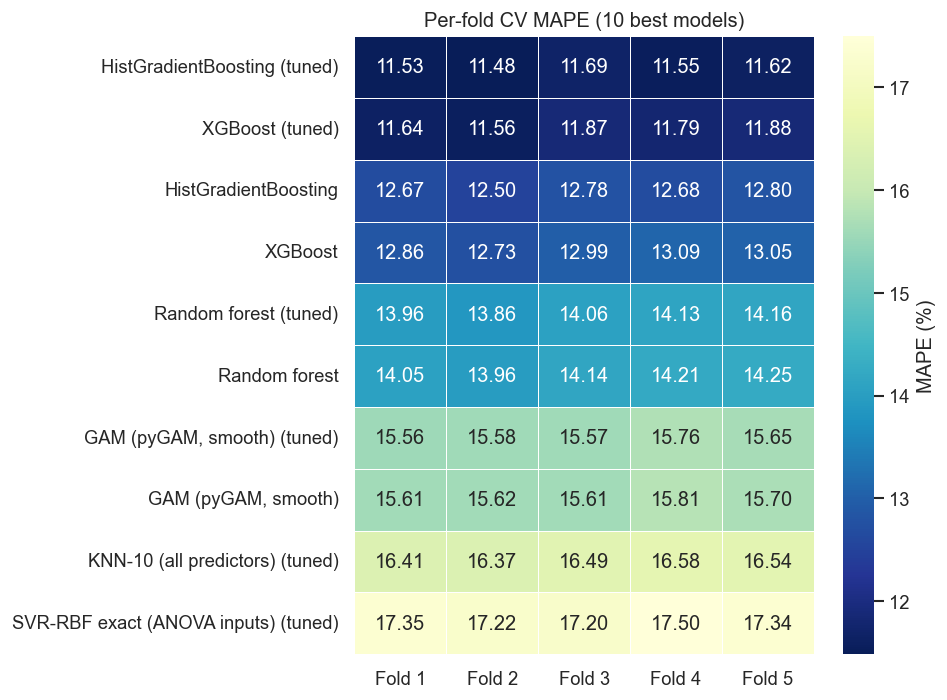

XGBoost (tuned) minus HistGradientBoosting (tuned): MAPE difference per fold = [0.112, 0.074, 0.176, 0.242, 0.258] pp  -> winner better in 5/5 folds


In [25]:
board = leaderboard()
display(fmt_board(board))
best_name = board.index[0]
print(f"\nBest by CV MAPE: {best_name}   (MAPE {board.loc[best_name, 'mape']:.2%}, RMSE ${board.loc[best_name, 'rmse']:,.0f}, R2 {board.loc[best_name, 'r2']:.4f})")

# per-fold MAPE heatmap for the 10 best models (same idea as the per-fold accuracy heatmap in the cancer notebook)
top = board.head(10).index
heat = pd.DataFrame({n: RESULTS[n]["mape"].values * 100 for n in top}, index=[f"Fold {i + 1}" for i in range(N_SPLITS)]).T
fig, ax = plt.subplots(figsize=(8, 0.45 * len(top) + 1.5))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="YlGnBu_r", linewidths=.5, cbar_kws={"label": "MAPE (%)"}, ax=ax)
ax.set_title("Per-fold CV MAPE (10 best models)"); plt.tight_layout(); plt.show()

# is the winner clearly ahead of the runner-up? (paired by fold)
if len(board) > 1:
    r1, r2_ = board.index[0], board.index[1]
    dd = RESULTS[r2_]["mape"].values - RESULTS[r1]["mape"].values
    print(f"{r2_} minus {r1}: MAPE difference per fold = {np.round(dd * 100, 3).tolist()} pp  -> winner better in {(dd > 0).sum()}/{N_SPLITS} folds")

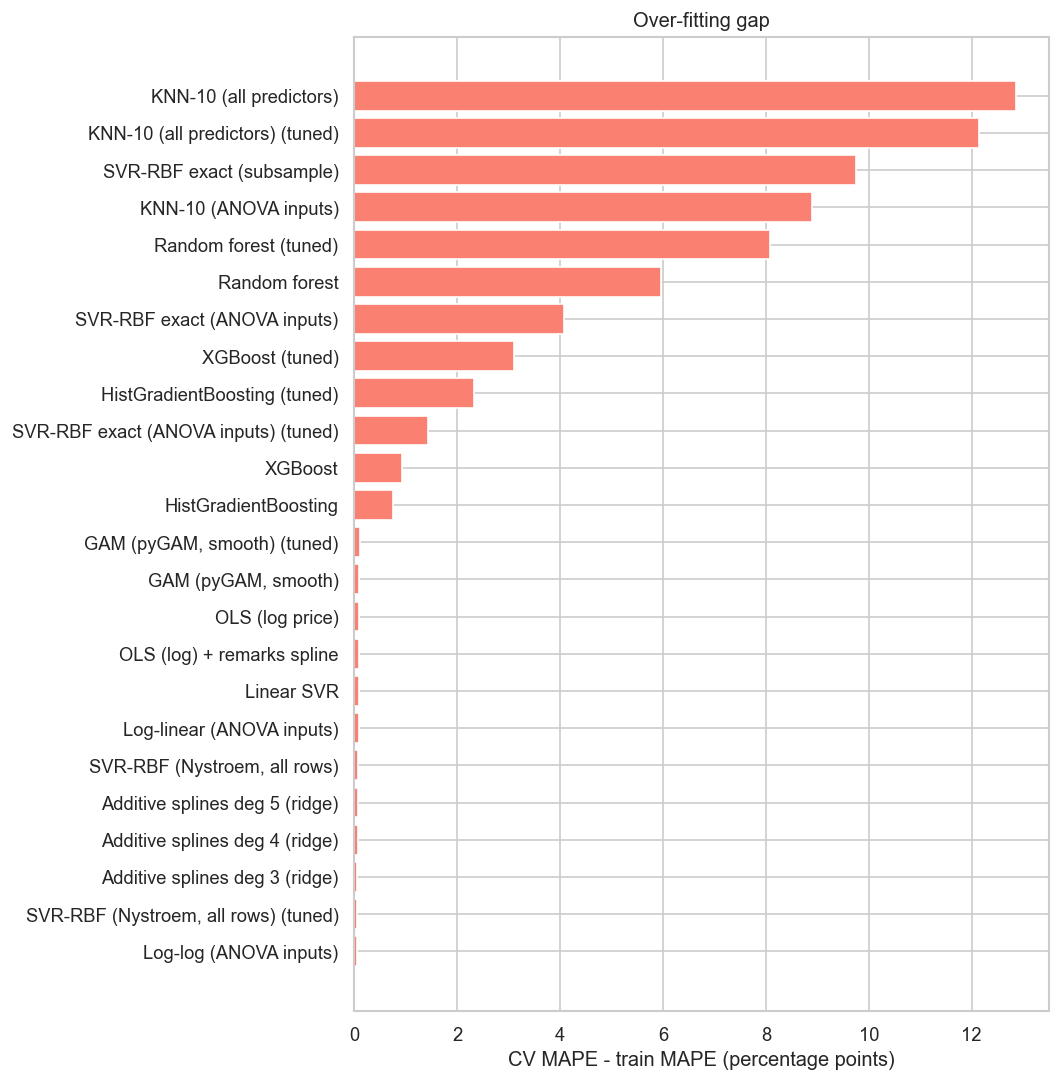

In [26]:
# Train vs CV error: which models over-fit?  (train score on a 10k subsample of each training fold)
gap = board[["train_mape", "mape"]].rename(columns={"mape": "cv_mape"})
gap["gap_pp"] = (gap["cv_mape"] - gap["train_mape"]) * 100
gap = gap.sort_values("gap_pp", ascending=False)
fig, ax = plt.subplots(figsize=(9, 0.32 * len(gap) + 1.5))
ax.barh(gap.index, gap["gap_pp"], color="salmon"); ax.invert_yaxis()
ax.set_xlabel("CV MAPE - train MAPE (percentage points)"); ax.set_title("Over-fitting gap")
plt.tight_layout(); plt.show()

## Error analysis of the best model (out-of-fold predictions)
Every prediction below comes from a fold in which that row was *not* used for training.

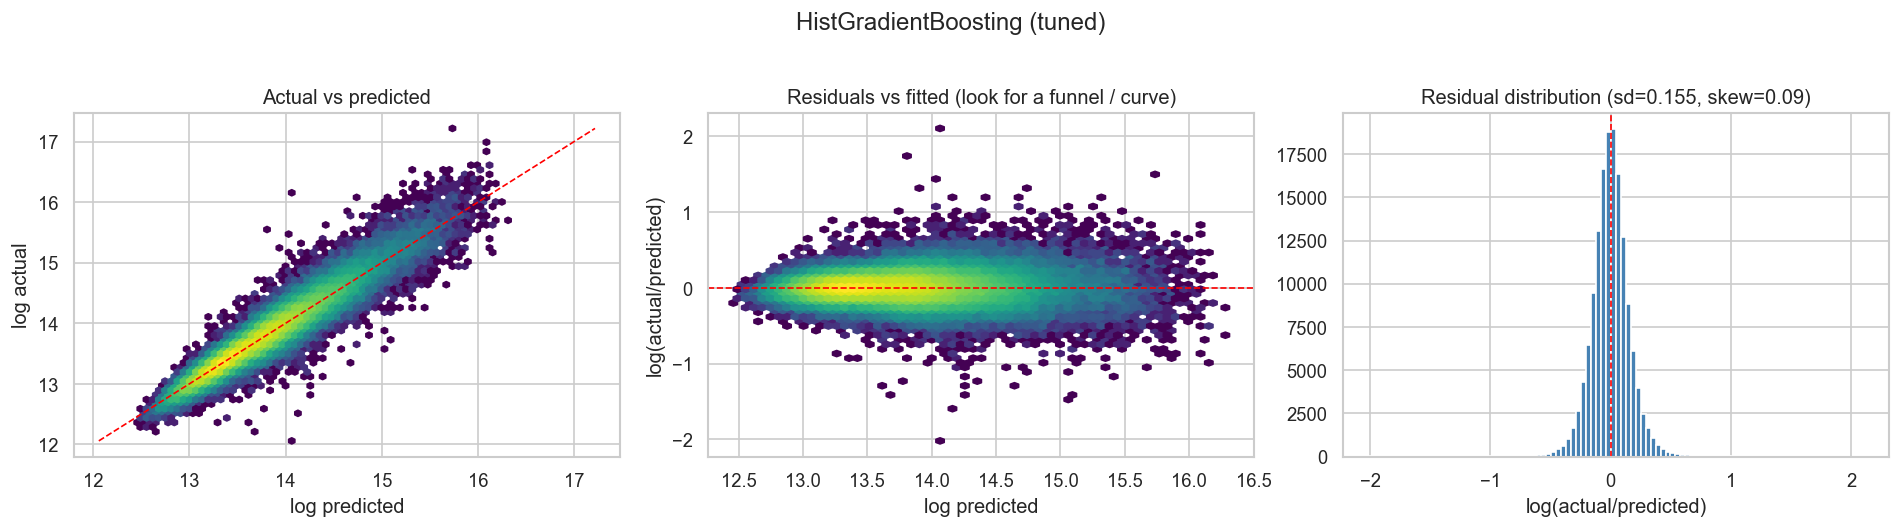

,n,MAPE,median APE,bias (median log ratio)
listing year,,,,
2020,1503,0.1078,0.0824,0.0011
2021,41867,0.1126,0.0865,-0.0001
2022,27402,0.1154,0.0884,0.0012
2023,24917,0.1157,0.0879,0.0001
2024,24553,0.1160,0.0884,0.0009
2025,22418,0.1197,0.0917,-0.0007
2026,7340,0.1235,0.0931,-0.0002


,n,MAPE,median APE,bias (median log ratio)
municipality (10 largest),,,,
York,1729,0.0987,0.0768,-0.0021
Etobicoke,14315,0.1101,0.0851,0.0003
Scarborough,21078,0.1122,0.0858,0.0008
North York,27555,0.1155,0.0875,0.0001
Toronto,85323,0.1180,0.0900,0.0002


,n,MAPE,median APE,bias (median log ratio)
price quintile,,,,
Q1 cheapest,30016,0.1006,0.0737,-0.0483
Q2,29997,0.0949,0.0698,-0.0054
Q3,29989,0.1096,0.0858,-0.0015
Q4,30000,0.1165,0.0958,0.0231
Q5 priciest,29998,0.1572,0.1313,0.0739


,n,MAPE,median APE,bias (median log ratio)
house type,,,,
Co-Op Apt,729,0.1430,0.1036,0.0008
Condo Apt,76374,0.0986,0.0753,0.0013
Condo Townhouse,10160,0.0972,0.0790,-0.0025
Detached,43202,0.1429,0.1139,-0.0006
Freehold Townhouse,5138,0.1305,0.1072,-0.0027
Semi-Detached,14397,0.1314,0.1047,-0.0012


Where an AVM exists: model MAPE 11.65% vs AVM 19.32%;  the model is closer than the AVM for 69.2% of listings

Largest relative errors (candidates for data-entry problems or unusual listings):


,ml_num,actual,predicted,ape,house_type,municipality,house_area,bedrooms,remarks_len
45777,SYN-0056216,172600.0,1299017.0,6.526,Condo Apt,Toronto,1689.0,3.0,347.0
73683,SYN-0087797,279800.0,1385190.0,3.951,Condo Apt,Toronto,1441.0,1.0,309.0
137167,SYN-0054443,777400.0,3428905.0,3.411,Semi-Detached,North York,4599.5,4.0,383.0
43127,SYN-0071856,205900.0,859870.0,3.176,Detached,Scarborough,599.5,2.0,308.0
21497,SYN-0128291,381800.0,1526833.0,2.999,Condo Apt,Toronto,1699.5,3.0,337.0
149497,SYN-0031235,892200.0,3542937.0,2.971,Detached,Toronto,1799.5,3.0,439.0
29723,SYN-0068047,635500.0,2352141.0,2.701,Condo Apt,Toronto,3390.0,3.0,426.0
56920,SYN-0049822,420600.0,1528755.0,2.635,Detached,Toronto,1619.0,4.0,442.0
143821,SYN-0138680,226200.0,807288.0,2.569,Condo Apt,North York,1299.5,2.0,302.0
82817,SYN-0145259,501500.0,1745985.0,2.482,Semi-Detached,Toronto,1799.5,4.0,389.0


In [27]:
p_best = np.maximum(OOF[best_name], 1.0)
lres = np.log(y.values) - np.log(p_best)                       # log(actual / predicted)  > 0 : under-predicted
ape  = np.abs(p_best - y.values) / y.values

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
hb = axes[0].hexbin(np.log(p_best), np.log(y.values), gridsize=60, bins="log", cmap="viridis")
lim = [min(np.log(p_best).min(), np.log(y).min()), max(np.log(p_best).max(), np.log(y).max())]
axes[0].plot(lim, lim, "r--", lw=1); axes[0].set_xlabel("log predicted"); axes[0].set_ylabel("log actual"); axes[0].set_title("Actual vs predicted")
axes[1].hexbin(np.log(p_best), lres, gridsize=60, bins="log", cmap="viridis"); axes[1].axhline(0, color="r", ls="--", lw=1)
axes[1].set_xlabel("log predicted"); axes[1].set_ylabel("log(actual/predicted)"); axes[1].set_title("Residuals vs fitted (look for a funnel / curve)")
axes[2].hist(lres, bins=100, color="steelblue", edgecolor="white"); axes[2].axvline(0, color="r", ls="--", lw=1)
axes[2].set_title(f"Residual distribution (sd={lres.std():.3f}, skew={stats.skew(lres):.2f})"); axes[2].set_xlabel("log(actual/predicted)")
plt.suptitle(best_name, y=1.02); plt.tight_layout(); plt.show()

def seg(by, label):
    g = pd.DataFrame({"seg": by, "ape": ape, "lres": lres}).groupby("seg", observed=True)
    out = pd.DataFrame({"n": g.size(), "MAPE": g["ape"].mean(), "median APE": g["ape"].median(), "bias (median log ratio)": g["lres"].median()})
    out.index.name = label
    return out

top_muni = X["municipality"].value_counts().head(10).index
display(seg(meta["year"], "listing year").round(4))
display(seg(X["municipality"].where(X["municipality"].isin(top_muni)), "municipality (10 largest)").sort_values("MAPE").round(4))
display(seg(pd.qcut(y, 5, labels=["Q1 cheapest", "Q2", "Q3", "Q4", "Q5 priciest"]), "price quintile").round(4))
display(seg(X["house_type_name"], "house type").round(4))

ok = X["avm_est"].notna().values
ape_avm = np.abs(X.loc[ok, "avm_est"].values - y.values[ok]) / y.values[ok]
print(f"Where an AVM exists: model MAPE {ape[ok].mean():.2%} vs AVM {ape_avm.mean():.2%};  the model is closer than the AVM for {(ape[ok] < ape_avm).mean():.1%} of listings")

worst = pd.DataFrame({"ml_num": raw["ml_num"], "actual": y, "predicted": p_best.round(0), "ape": ape.round(3), "house_type": X["house_type_name"],
                      "municipality": X["municipality"], "house_area": X["house_area"], "bedrooms": X["bedrooms"], "remarks_len": X["remarks_len"]})
print("\nLargest relative errors (candidates for data-entry problems or unusual listings):")
display(worst.sort_values("ape", ascending=False).head(12))

## Does `remarks_len` carry information beyond the structured columns?
The marginal relationship (earlier section) can be pure confounding with house size. Two tests with a gradient-boosted model, on identical folds:

1. **Ablation** – same model with and without `remarks_len`, compared fold by fold and on out-of-fold errors.
2. **Residual check** – if the length adds nothing, the residuals of the model *without* it should be flat in `remarks_len`.

  HGB without remarks_len                      RMSE=   317,330  MAPE=11.51%  R2=0.8473  (31s)

Per-fold RMSE improvement from remarks_len ($): [1549.0, -804.0, -1038.0, -465.0, 1134.0]
MAPE with 11.574%  vs without 11.505%
Mean reduction in |log error| per listing: -0.00070  (95% CI -0.00086 .. -0.00054)


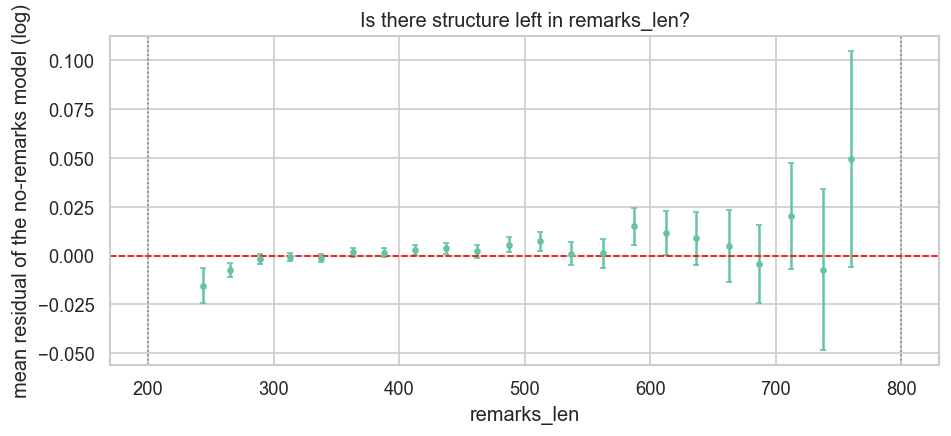

Spearman(remarks_len, residual of the model without it) = 0.0186  (p = 5.54e-13)


In [28]:
hgb_name = "HistGradientBoosting (tuned)" if "HistGradientBoosting (tuned)" in RESULTS else "HistGradientBoosting"
hgb_est  = EST[hgb_name]
hgb_core = clone(hgb_est.regressor.named_steps["model"])
no_rl    = [c for c in ALL_FEATS if c != "remarks_len"]
run_cv("HGB without remarks_len", wrap(pipe("tree", hgb_core, keep=no_rl)))

with_, wo = RESULTS[hgb_name], RESULTS["HGB without remarks_len"]
print(f"\nPer-fold RMSE improvement from remarks_len ($): {(wo['rmse'] - with_['rmse']).round(0).tolist()}")
print(f"MAPE with {with_.mape.mean():.3%}  vs without {wo.mape.mean():.3%}")
e_with, e_wo = np.abs(np.log(np.maximum(OOF[hgb_name], 1)) - np.log(y.values)), np.abs(np.log(np.maximum(OOF["HGB without remarks_len"], 1)) - np.log(y.values))
dlt = e_wo - e_with
se = dlt.std() / np.sqrt(len(dlt))
print(f"Mean reduction in |log error| per listing: {dlt.mean():.5f}  (95% CI {dlt.mean() - 1.96 * se:.5f} .. {dlt.mean() + 1.96 * se:.5f})")

# residual check on the model WITHOUT remarks_len
r_wo = np.log(y.values) - np.log(np.maximum(OOF["HGB without remarks_len"], 1))
bins = pd.cut(X["remarks_len"], bins=np.arange(X["remarks_len"].min() // 25 * 25, X["remarks_len"].max() + 25, 25))
rb = pd.DataFrame({"bin": bins, "x": X["remarks_len"], "r": r_wo}).groupby("bin", observed=True).agg(x=("x", "mean"), m=("r", "mean"), se=("r", lambda v: v.std() / np.sqrt(len(v))), n=("r", "size"))
rb = rb[rb["n"] >= 30]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.errorbar(rb["x"], rb["m"], yerr=1.96 * rb["se"], fmt="o", ms=3, capsize=2); ax.axhline(0, color="r", ls="--", lw=1)
for v in REMARKS_RANGE: ax.axvline(v, color="grey", ls=":", lw=1)
ax.set_xlabel("remarks_len"); ax.set_ylabel("mean residual of the no-remarks model (log)"); ax.set_title("Is there structure left in remarks_len?")
plt.tight_layout(); plt.show()
rho, pv = stats.spearmanr(X["remarks_len"], r_wo)
print(f"Spearman(remarks_len, residual of the model without it) = {rho:.4f}  (p = {pv:.2e})")

## Explainability: permutation importance and SHAP

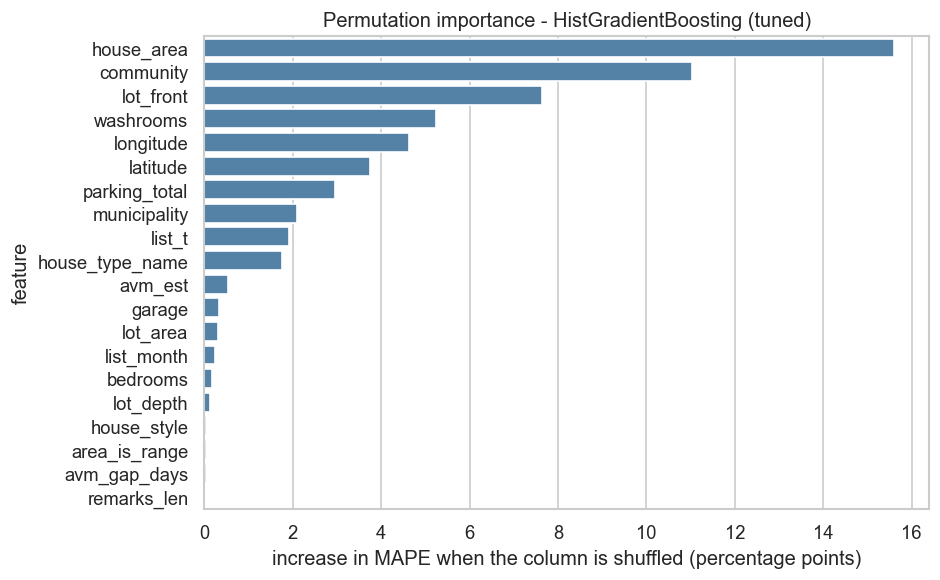

In [29]:
# Permutation importance of the ORIGINAL columns (the whole pipeline sees the permuted raw column), fold-0 test rows
tr0, te0 = next(iter(cv.split(X)))
m0 = clone(EST[best_name]).fit(X.iloc[tr0], y.iloc[tr0])
te_s = np.random.default_rng(SEED).choice(te0, size=min(8000, len(te0)), replace=False)
pi = permutation_importance(m0, X.iloc[te_s], y.iloc[te_s], scoring="neg_mean_absolute_percentage_error", n_repeats=3, random_state=SEED, n_jobs=1)
pim = pd.DataFrame({"feature": X.columns, "mape_increase_pp": pi.importances_mean * 100}).sort_values("mape_increase_pp", ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=pim, x="mape_increase_pp", y="feature", color="steelblue", ax=ax)
ax.set_xlabel("increase in MAPE when the column is shuffled (percentage points)"); ax.set_title(f"Permutation importance - {best_name}")
plt.tight_layout(); plt.show()

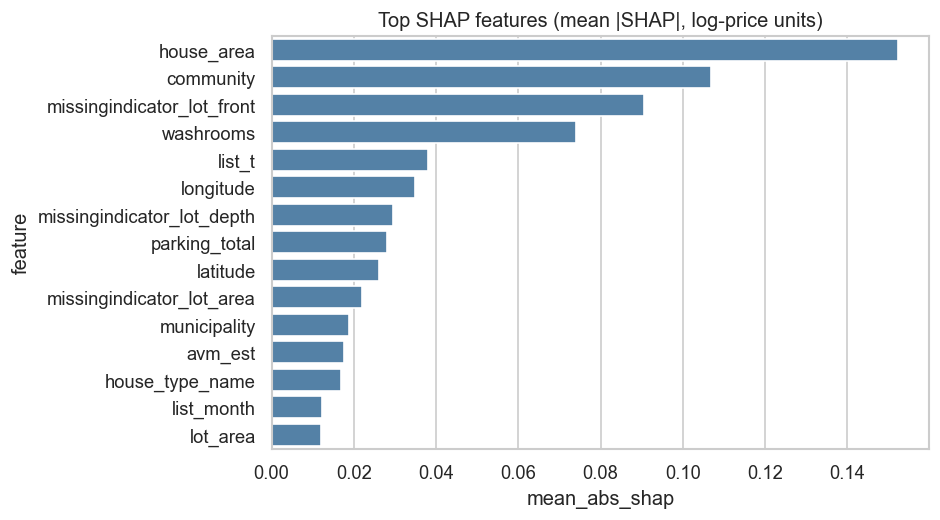

Top drivers of one listing (row 89913): predicted price = actual-scale exp(base + sum of SHAP)


,feature,value,shap
3,house_area,699.5000,-0.2093
1,washrooms,1.0000,-0.1184
14,missingindicator_lot_front,1.0000,-0.0741
22,municipality,3.0000,0.0337
24,community,13.5182,-0.0283
15,missingindicator_lot_depth,1.0000,-0.0233
16,missingindicator_lot_area,1.0000,-0.0186
19,house_type_name,0.0000,0.0179
4,area_is_range,1.0000,-0.0087
8,latitude,43.6607,-0.0086


In [30]:
# SHAP for the boosted-tree model (optional dependency: pip install shap). Values are on the log-price scale,
# i.e. approximately "percent effect on the price".
try:
    import shap
except ImportError:
    shap = None
    print("shap is not installed. Run: pip install shap")

if shap is not None:
    xgb_key = "XGBoost (tuned)" if "XGBoost (tuned)" in EST else "XGBoost"
    mx = clone(EST[xgb_key]).fit(X.iloc[tr0], y.iloc[tr0])
    prep_x, booster = mx.regressor_.named_steps["prep"], mx.regressor_.named_steps["model"]
    names = prep_x.get_feature_names_out()
    samp = np.random.default_rng(SEED).choice(te0, size=min(3000, len(te0)), replace=False)
    A_ = pd.DataFrame(prep_x.transform(X.iloc[samp]), columns=names)
    sv = shap.TreeExplainer(booster).shap_values(A_)
    imp = pd.DataFrame({"feature": names, "mean_abs_shap": np.abs(sv).mean(0)}).sort_values("mean_abs_shap", ascending=False).head(15)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    sns.barplot(data=imp, x="mean_abs_shap", y="feature", color="steelblue", ax=ax)
    ax.set_title("Top SHAP features (mean |SHAP|, log-price units)"); plt.tight_layout(); plt.show()
    i0 = 0
    contrib = pd.DataFrame({"feature": names, "value": A_.iloc[i0].values, "shap": sv[i0]}).assign(abs_shap=lambda d: d["shap"].abs()).sort_values("abs_shap", ascending=False).head(10)
    print(f"Top drivers of one listing (row {samp[i0]}): predicted price = actual-scale exp(base + sum of SHAP)")
    display(contrib[["feature", "value", "shap"]].round(4))

## Prediction intervals (split-conformal, from the out-of-fold residuals)
The cancer notebook reported a calibrated confidence for each prediction; the regression analogue is an interval around the price. For fold *k* the 90% half-width (in log units) is the 90% quantile of |log(actual/predicted)| computed on the **other four folds'** out-of-fold residuals, then its coverage is checked on fold *k*. The interval is multiplicative: `[pred·e^-q, pred·e^q]`.

In [31]:
abs_res = np.abs(lres)
cover, width = np.zeros(len(y), dtype=bool), np.zeros(len(y))
for k in range(N_SPLITS):
    q = np.quantile(abs_res[FOLD_ID != k], 0.90)
    cover[FOLD_ID == k] = abs_res[FOLD_ID == k] <= q
    width[FOLD_ID == k] = np.exp(q) - np.exp(-q)
print(f"Nominal 90% interval -> empirical coverage {cover.mean():.1%};  typical interval: ±{np.exp(np.quantile(abs_res, .9)) - 1:.1%}")
qint = pd.qcut(y, 5, labels=["Q1 cheapest", "Q2", "Q3", "Q4", "Q5 priciest"])
display(pd.DataFrame({"coverage": pd.Series(cover).groupby(qint.values, observed=True).mean(),
                      "median |log err|": pd.Series(abs_res).groupby(qint.values, observed=True).median()}).round(3))
print("If coverage differs a lot between price bands, the error is heteroscedastic -> consider quantile models or a conformal scale per segment.")

Nominal 90% interval -> empirical coverage 90.0%;  typical interval: ±27.5%


,coverage,median |log err|
Q1 cheapest,0.949,0.073
Q2,0.947,0.070
Q3,0.927,0.086
Q4,0.906,0.097
Q5 priciest,0.771,0.135


If coverage differs a lot between price bands, the error is heteroscedastic -> consider quantile models or a conformal scale per segment.


## Does time matter? A forward-in-time check
Random 5-fold CV mixes all years, which flatters a model on a market that trends. Here the best model is trained on everything listed up to 12 months before the end of the data and tested on the final 12 months.

Train: 129,920 rows (< 2025-05-29)   Test: 20,080 rows (last 12 months)
Forward-in-time:  MAPE 13.06%   RMSE $328,858   R2 0.8460
Random 5-fold CV: MAPE 11.57%   RMSE $317,255   R2 0.8474


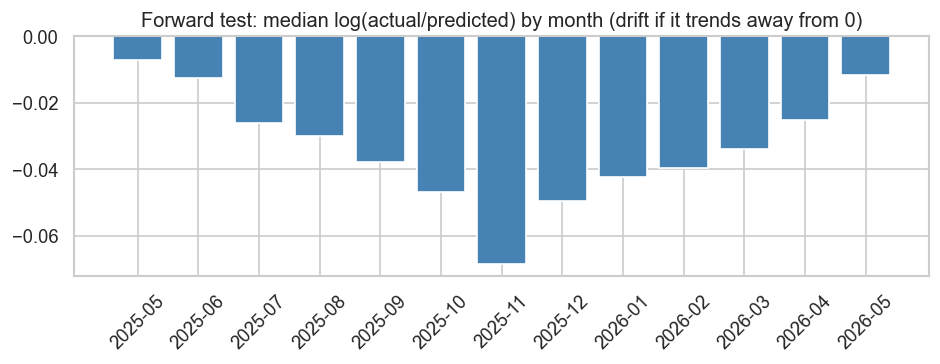

In [32]:
cut = meta["date_listed"].max() - pd.DateOffset(months=12)
tr_t, te_t = np.where(meta["date_listed"] < cut)[0], np.where(meta["date_listed"] >= cut)[0]
mt = clone(EST[best_name]).fit(X.iloc[tr_t], y.iloc[tr_t])
pt = mt.predict(X.iloc[te_t])
fw = metrics(y.iloc[te_t].values, pt)
print(f"Train: {len(tr_t):,} rows (< {cut.date()})   Test: {len(te_t):,} rows (last 12 months)")
print(f"Forward-in-time:  MAPE {fw['mape']:.2%}   RMSE ${fw['rmse']:,.0f}   R2 {fw['r2']:.4f}")
print(f"Random 5-fold CV: MAPE {board.loc[best_name, 'mape']:.2%}   RMSE ${board.loc[best_name, 'rmse']:,.0f}   R2 {board.loc[best_name, 'r2']:.4f}")
bias = pd.DataFrame({"m": meta["date_listed"].iloc[te_t].dt.to_period("M").astype(str).values, "r": np.log(y.iloc[te_t].values) - np.log(pt)}).groupby("m")["r"].median()
fig, ax = plt.subplots(figsize=(8, 3.2)); ax.bar(bias.index, bias.values, color="steelblue"); ax.axhline(0, color="r", lw=1)
ax.set_title("Forward test: median log(actual/predicted) by month (drift if it trends away from 0)"); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## Final model, saved artefact, and a prediction helper

In [33]:
final_model = clone(EST[best_name]).fit(X, y)                      # trained on all rows
joblib.dump({"model": final_model, "features": ALL_FEATS, "target": TARGET, "keep": KEEP, "cv_mape": float(board.loc[best_name, "mape"])},
            "gta_price_model.joblib")
print(f"Saved gta_price_model.joblib  ({best_name})")
# note: to joblib.load() this file in a new session, first run the cells that define GAMReg / SubsampleFit (custom classes)

def predict_price(new_raw: pd.DataFrame, interval=0.90):
    """new_raw: dataframe with the ORIGINAL listing columns (remarks, house_area ranges, ... exactly as in the csv)."""
    Xn = engineer(new_raw)
    pred = final_model.predict(Xn)
    q = np.quantile(abs_res, interval)
    return pd.DataFrame({"predicted": pred.round(-3), "low": (pred * np.exp(-q)).round(-3), "high": (pred * np.exp(q)).round(-3)}, index=new_raw.index)

display(pd.concat([raw[["ml_num", TARGET]].head(5), predict_price(raw.head(5))], axis=1))

Saved gta_price_model.joblib  (HistGradientBoosting (tuned))


,ml_num,sold_price,predicted,low,high
0,SYN-0023247,364100.0,400000.0,314000.0,510000.0
1,SYN-0156988,599000.0,580000.0,454000.0,739000.0
2,SYN-0087706,492900.0,488000.0,382000.0,622000.0
3,SYN-0128154,532300.0,658000.0,516000.0,839000.0
4,SYN-0118596,564100.0,556000.0,436000.0,709000.0


## Summary

In [34]:
top3 = board.head(3)
fam = {"OLS": "Linear", "Log-": "Log regression (ANOVA inputs)", "Additive": "Additive splines", "GAM": "Additive (GAM)", "Random": "Random forest",
       "XGB": "XGBoost", "Hist": "Histogram boosting", "KNN": "KNN", "Linear SVR": "SVM", "SVR": "SVM"}
def best_in(prefixes):
    names = [n for n in board.index if any(n.startswith(p) for p in prefixes)]
    return (names[0], board.loc[names[0], "mape"]) if names else ("-", np.nan)
rows = []
for label, pref in [("Linear regression", ["OLS"]), ("Log regression (ANOVA inputs)", ["Log-"]), ("Additive (splines / GAM)", ["Additive", "GAM"]),
                    ("Random forest", ["Random"]), ("XGBoost", ["XGB"]), ("Histogram boosting", ["Hist"]), ("KNN", ["KNN"]), ("SVM / SVR", ["Linear SVR", "SVR"])]:
    n, m = best_in(pref); rows.append(f"| {label} | {n} | {m:.2%} |")

avm_txt = f"AVM used directly: MAPE {ape_avm.mean():.2%} on the {ok.mean():.0%} of rows where it exists." if ok.any() else ""
md_txt = f"""
| Step | Detail |
|------|--------|
| **Data** | {len(X):,} listings x {len(ALL_FEATS)} predictors, target `{TARGET}` (log-transformed for modelling), Jan 2021 - May 2026 |
| **Validation** | {N_SPLITS}-fold shuffled CV on all rows, all preprocessing inside the pipeline; tuning on a separate 30k sample |
| **ANOVA (Type II, log price)** | strongest terms: {', '.join(anova_tab[~anova_tab['joint']].head(5)['term'])};  predictors used in the log regression: {len(KEEP)} of {len(ALL_FEATS)} |
| **remarks_len** | best non-smoothing spline: degree {REMARKS_SPLINE['degree']}, {REMARKS_SPLINE['n_knots']} knots; ablation: MAPE {wo.mape.mean():.3%} without vs {with_.mape.mean():.3%} with it; residual correlation without it: {rho:.3f} |
| **Best model** | **{best_name}**: MAPE {board.loc[best_name, 'mape']:.2%}, median APE {board.loc[best_name, 'medape']:.2%}, RMSE ${board.loc[best_name, 'rmse']:,.0f}, R2 {board.loc[best_name, 'r2']:.4f}, {board.loc[best_name, 'within10']:.0%} of listings within 10% |
| **Benchmark** | {avm_txt} |
| **Forward-in-time test** | MAPE {fw['mape']:.2%} on the last 12 months (random CV: {board.loc[best_name, 'mape']:.2%}) |
| **90% interval** | empirical coverage {cover.mean():.1%} |

| Family | Best variant | CV MAPE |
|---|---|---|
""" + "\n".join(rows)
display(Markdown(md_txt))


| Step | Detail |
|------|--------|
| **Data** | 150,000 listings x 20 predictors, target `sold_price` (log-transformed for modelling), Jan 2021 - May 2026 |
| **Validation** | 5-fold shuffled CV on all rows, all preprocessing inside the pipeline; tuning on a separate 30k sample |
| **ANOVA (Type II, log price)** | strongest terms: community, washrooms, house_area, list_t, parking_total;  predictors used in the log regression: 10 of 20 |
| **remarks_len** | best non-smoothing spline: degree 3, 8 knots; ablation: MAPE 11.505% without vs 11.574% with it; residual correlation without it: 0.019 |
| **Best model** | **HistGradientBoosting (tuned)**: MAPE 11.57%, median APE 8.83%, RMSE $317,255, R2 0.8474, 55% of listings within 10% |
| **Benchmark** | AVM used directly: MAPE 19.32% on the 29% of rows where it exists. |
| **Forward-in-time test** | MAPE 13.06% on the last 12 months (random CV: 11.57%) |
| **90% interval** | empirical coverage 90.0% |

| Family | Best variant | CV MAPE |
|---|---|---|
| Linear regression | OLS (log price) | 19.43% |
| Log regression (ANOVA inputs) | Log-log (ANOVA inputs) | 18.99% |
| Additive (splines / GAM) | GAM (pyGAM, smooth) (tuned) | 15.63% |
| Random forest | Random forest (tuned) | 14.03% |
| XGBoost | XGBoost (tuned) | 11.75% |
| Histogram boosting | HistGradientBoosting (tuned) | 11.57% |
| KNN | KNN-10 (all predictors) (tuned) | 16.48% |
| SVM / SVR | SVR-RBF exact (ANOVA inputs) (tuned) | 17.32% |

### Ideas for the next iteration
* **Tell the ANOVA story in your report**: the effect-size columns, not the p-values, are what separate the predictors at this sample size; the location block is the one to look at as a whole.
* **Native categorical handling** (LightGBM / HistGradientBoosting `categorical_features`) for `municipality` and `house_type_name`, and a lat/lon → distance-to-downtown feature, are the cheapest likely gains for the tree models.
* **Quantile or conformalised-quantile boosting** if the coverage-by-price-band table shows that the error grows with price.
* **Stacking** (ridge on the out-of-fold predictions that are already stored in `OOF`) – the stored out-of-fold predictions make this a few lines.
* If the forward-in-time test is much worse than random CV, add a market-index feature (rolling median price by municipality up to the listing date) instead of relying on `list_t` alone.